In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [2]:
one_point_without_outliers = pd.read_parquet('../data/diff_then_one_point_countries_then_delete_zeros_then_win7_then_delete_7features_3countries_of_hpi_deleted.parquet')

In [3]:
one_point_without_outliers.head()

,Country,labor_force_std,labor_force_max,livestock_prod_std,gov_exp_mean,gov_exp_median,gov_exp_std,gov_exp_cv,gov_exp_max,gov_exp_trend,...,edu_spending_df_skew,edu_spending_df_kurtosis,edu_spending_df_trend,govermment_effective_df_mean,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.143977,0.357674,1.554548,2.136767,2.262414,1.507192,0.385463,2.615569,0.755168,...,0.493104,-1.488040,0.063886,0.567630,0.796482,0.570699,-1.003472,-0.783260,-0.276379,0.521790
1,Austria,0.029299,0.067659,0.668800,0.666803,0.546675,0.496587,0.517829,1.145019,0.177893,...,-1.199757,1.294932,-0.427952,-0.287040,-0.262984,0.232113,-0.145665,0.269123,-0.196556,-1.047159
2,Belgium,0.041506,0.104360,1.147336,0.805024,0.665262,0.630444,0.536660,1.345472,0.230306,...,0.667567,1.020573,0.045669,-1.227178,-0.085868,-0.445060,0.140270,0.016105,-0.586669,0.435584
3,Brazil,0.529323,1.280934,1.040778,3.281428,3.129935,2.842337,0.489039,4.064830,1.701274,...,-0.355222,-1.696472,0.011514,-0.970776,-0.261347,-1.009370,1.998852,0.899841,0.389117,0.263172
4,Bulgaria,0.055988,0.086178,1.198873,0.493476,0.488580,0.353456,0.509553,0.896088,0.131639,...,0.350505,0.039883,0.425933,0.140295,-0.564445,-1.009370,1.998852,-0.480145,1.141334,1.314885


### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [4]:
from sklearn.cluster import KMeans

#### one_point_without_outliers

In [5]:
cluster_input = one_point_without_outliers.select_dtypes(include='number')
cluster_input.head()

,labor_force_std,labor_force_max,livestock_prod_std,gov_exp_mean,gov_exp_median,gov_exp_std,gov_exp_cv,gov_exp_max,gov_exp_trend,reserves_std,...,edu_spending_df_skew,edu_spending_df_kurtosis,edu_spending_df_trend,govermment_effective_df_mean,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,0.143977,0.357674,1.554548,2.136767,2.262414,1.507192,0.385463,2.615569,0.755168,1.971041,...,0.493104,-1.488040,0.063886,0.567630,0.796482,0.570699,-1.003472,-0.783260,-0.276379,0.521790
1,0.029299,0.067659,0.668800,0.666803,0.546675,0.496587,0.517829,1.145019,0.177893,1.224077,...,-1.199757,1.294932,-0.427952,-0.287040,-0.262984,0.232113,-0.145665,0.269123,-0.196556,-1.047159
2,0.041506,0.104360,1.147336,0.805024,0.665262,0.630444,0.536660,1.345472,0.230306,1.266031,...,0.667567,1.020573,0.045669,-1.227178,-0.085868,-0.445060,0.140270,0.016105,-0.586669,0.435584
3,0.529323,1.280934,1.040778,3.281428,3.129935,2.842337,0.489039,4.064830,1.701274,2.542621,...,-0.355222,-1.696472,0.011514,-0.970776,-0.261347,-1.009370,1.998852,0.899841,0.389117,0.263172
4,0.055988,0.086178,1.198873,0.493476,0.488580,0.353456,0.509553,0.896088,0.131639,1.260348,...,0.350505,0.039883,0.425933,0.140295,-0.564445,-1.009370,1.998852,-0.480145,1.141334,1.314885


#### Using the elbow method to find the optimal number of clusters

In [6]:
distortions = []

In [7]:
import time

In [8]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


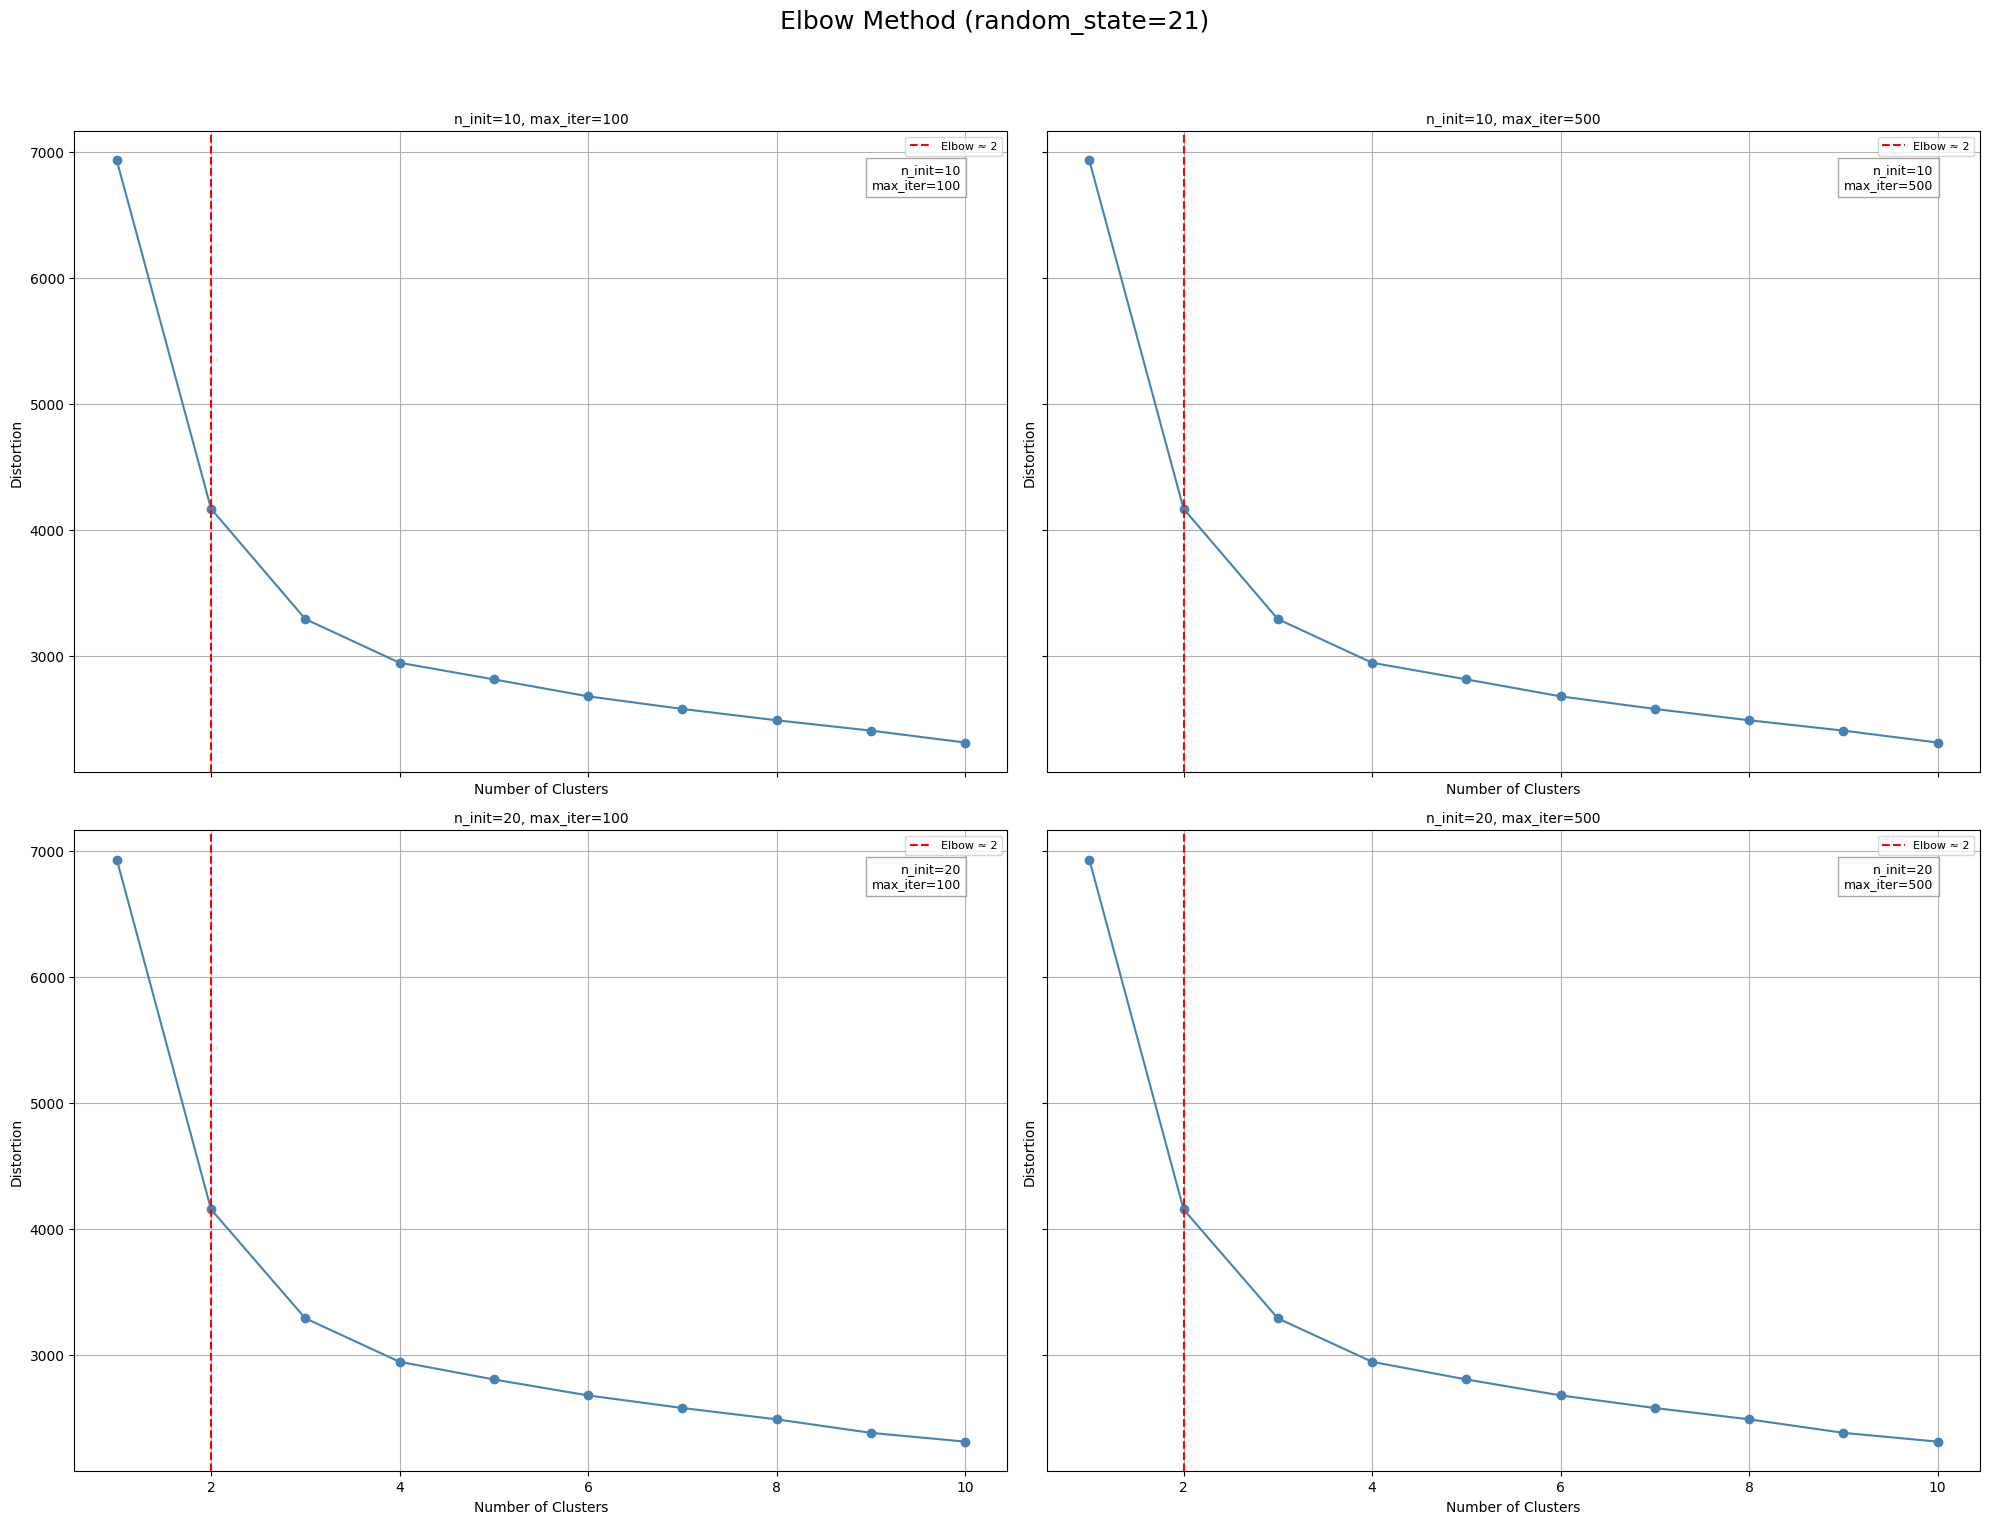


Running elbow plots for random_state=42


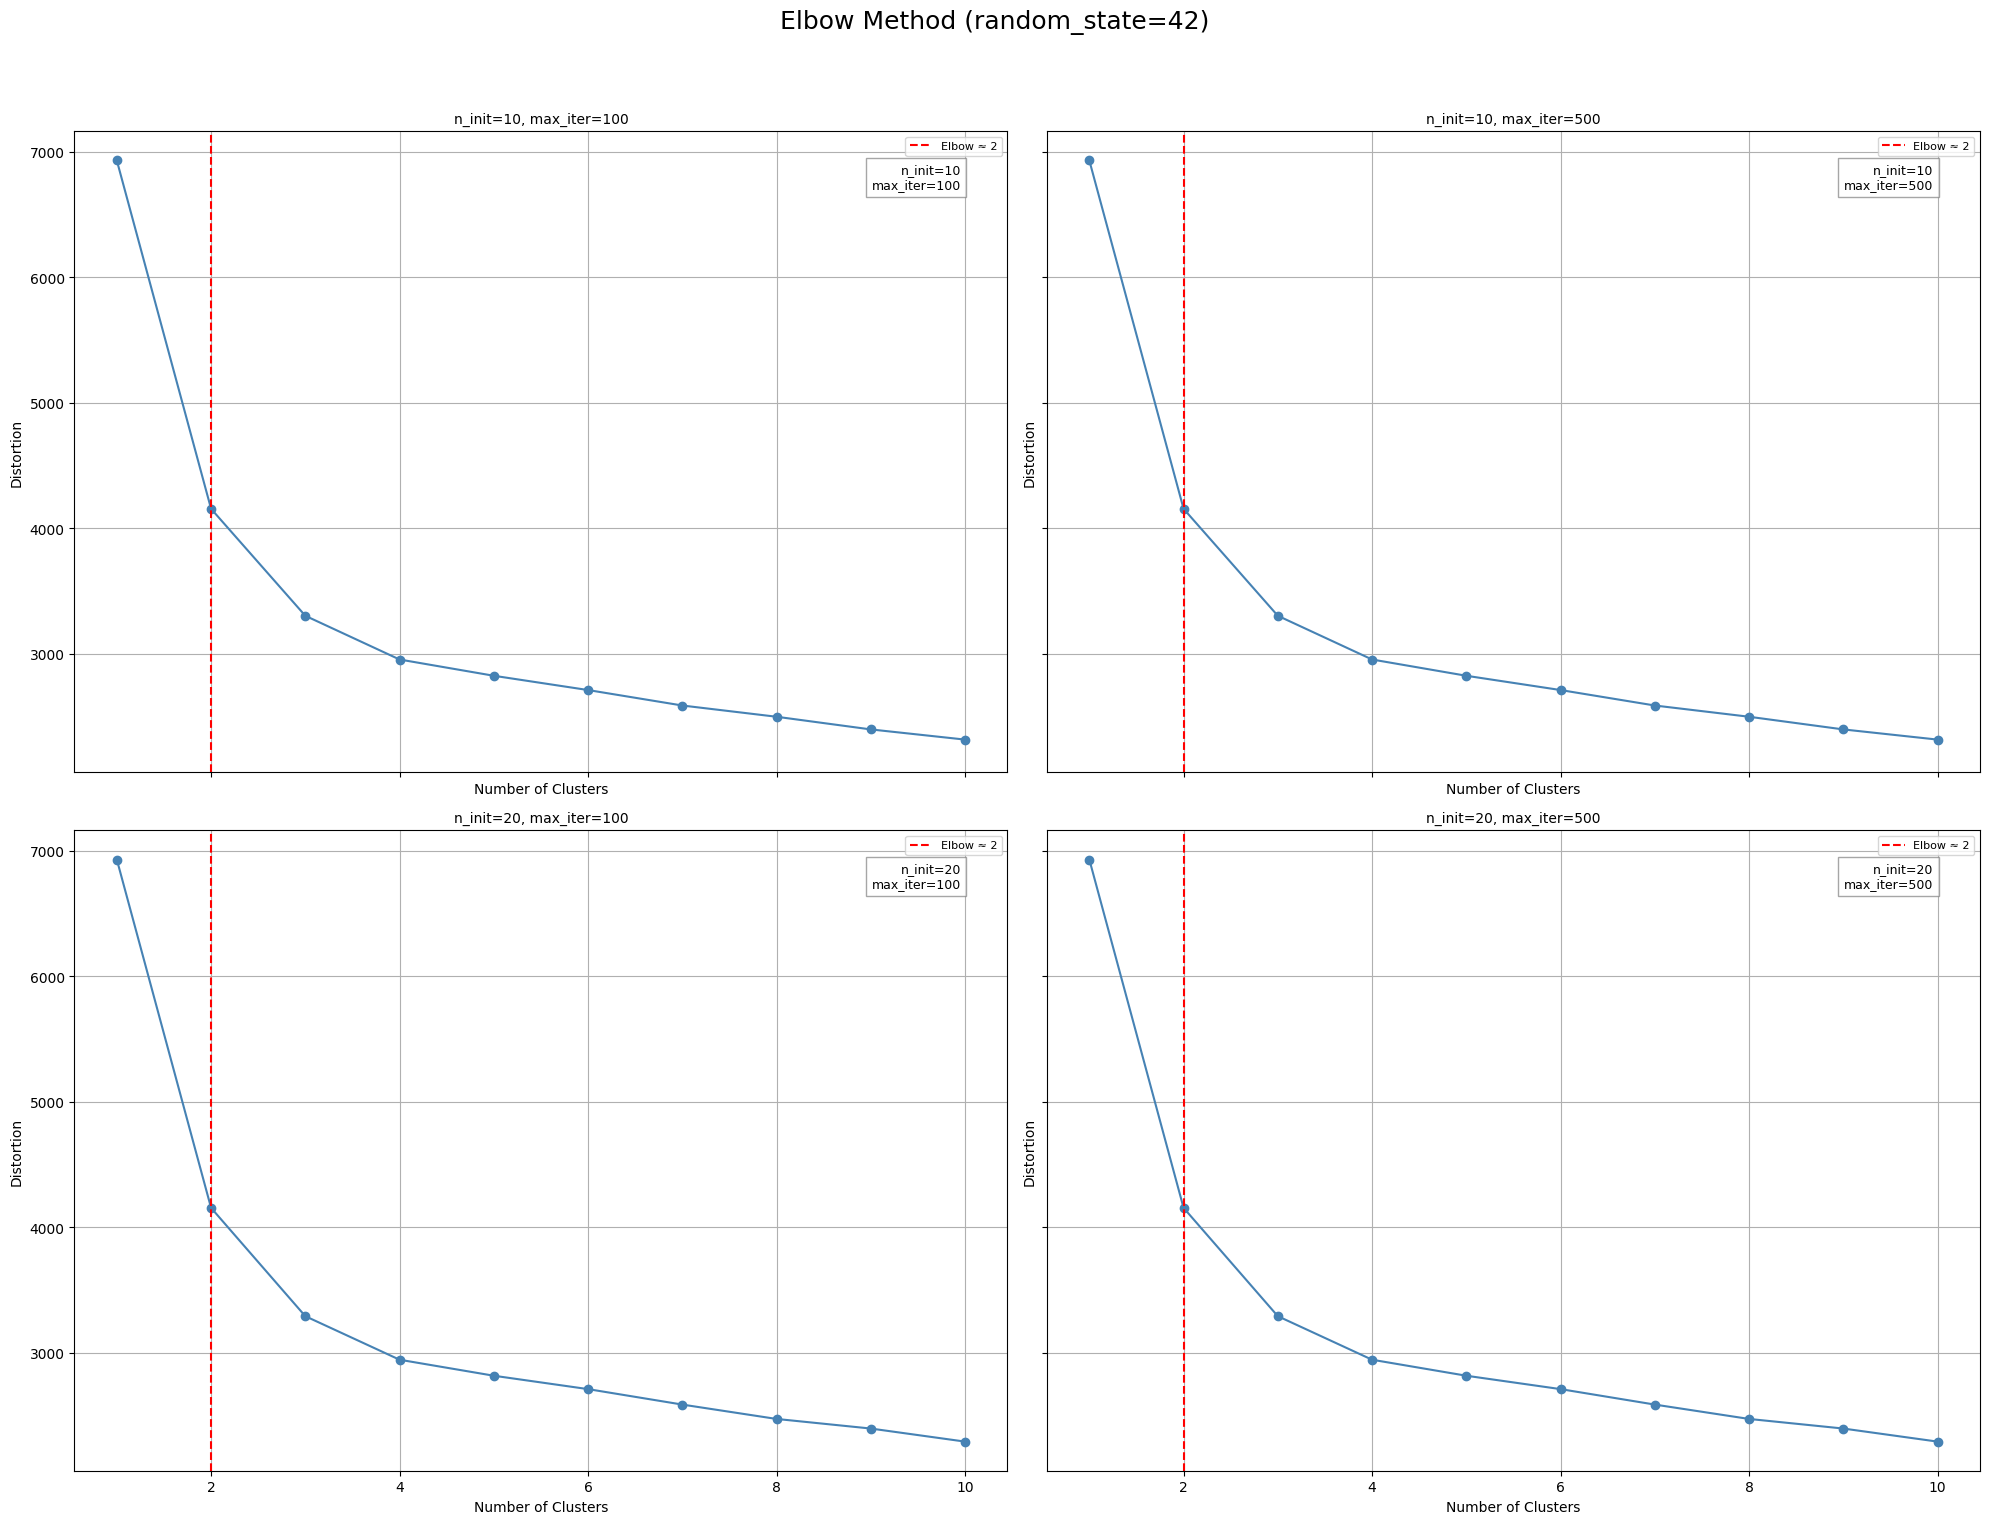


Total execution time: 5.94 seconds


In [9]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [10]:
from sklearn.metrics import silhouette_samples

In [11]:
from matplotlib import cm

In [12]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [13]:
km_c2_ni20_maxi500 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [15]:
ym_c2_ni20_maxi500 = km_c2_ni20_maxi500.fit(cluster_input)

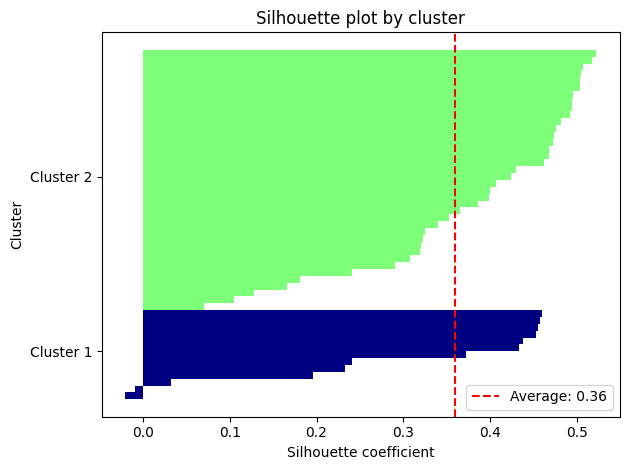

In [16]:
silhoutte_c2_ni20_maxi500 = plot_silhouette(ym_c2_ni20_maxi500, cluster_input)

In [17]:
np.bincount(ym_c2_ni20_maxi500.labels_)

array([13, 38])

In [18]:
c2_ni20_maxi500 = one_point_without_outliers.copy()

In [19]:
c2_ni20_maxi500['cluster'] = ym_c2_ni20_maxi500.labels_

In [20]:
import country_converter as coco

In [21]:
c2_ni20_maxi500.head()

,Country,labor_force_std,labor_force_max,livestock_prod_std,gov_exp_mean,gov_exp_median,gov_exp_std,gov_exp_cv,gov_exp_max,gov_exp_trend,...,edu_spending_df_kurtosis,edu_spending_df_trend,govermment_effective_df_mean,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend,cluster
0,Australia,0.143977,0.357674,1.554548,2.136767,2.262414,1.507192,0.385463,2.615569,0.755168,...,-1.488040,0.063886,0.567630,0.796482,0.570699,-1.003472,-0.783260,-0.276379,0.521790,1
1,Austria,0.029299,0.067659,0.668800,0.666803,0.546675,0.496587,0.517829,1.145019,0.177893,...,1.294932,-0.427952,-0.287040,-0.262984,0.232113,-0.145665,0.269123,-0.196556,-1.047159,1
2,Belgium,0.041506,0.104360,1.147336,0.805024,0.665262,0.630444,0.536660,1.345472,0.230306,...,1.020573,0.045669,-1.227178,-0.085868,-0.445060,0.140270,0.016105,-0.586669,0.435584,1
3,Brazil,0.529323,1.280934,1.040778,3.281428,3.129935,2.842337,0.489039,4.064830,1.701274,...,-1.696472,0.011514,-0.970776,-0.261347,-1.009370,1.998852,0.899841,0.389117,0.263172,0
4,Bulgaria,0.055988,0.086178,1.198873,0.493476,0.488580,0.353456,0.509553,0.896088,0.131639,...,0.039883,0.425933,0.140295,-0.564445,-1.009370,1.998852,-0.480145,1.141334,1.314885,1


In [22]:
c2_ni20_maxi500['ISO_A3'] = coco.convert(names=c2_ni20_maxi500['Country'], to='ISO3')

In [23]:
c2_ni20_maxi500 = c2_ni20_maxi500[['Country', 'ISO_A3', 'cluster']].copy()

In [24]:
c2_ni20_maxi500.loc[:, 'Continent'] = coco.convert(
    names=c2_ni20_maxi500['Country'], to='continent'
)

In [25]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [26]:
print_cluster_groups(c2_ni20_maxi500)


🌍 Cluster 0 (13 countries):
 - Brazil (America)
 - Chile (America)
 - Colombia (America)
 - Hungary (Europe)
 - Japan (Asia)
 - Mexico (America)
 - Paraguay (America)
 - Philippines (Asia)
 - Russia (Europe)
 - Serbia (Europe)
 - South Korea (Asia)
 - Thailand (Asia)
 - USA (America)

🌍 Cluster 1 (38 countries):
 - Australia (Oceania)
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Canada (America)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Czech Republic (Europe)
 - Denmark (Europe)
 - Estonia (Europe)
 - Finland (Europe)
 - France (Europe)
 - Germany (Europe)
 - Greece (Europe)
 - Iceland (Europe)
 - Ireland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malaysia (Asia)
 - Malta (Europe)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Norway (Europe)
 - Peru (America)
 - Poland (Europe)
 - Portugal (Europe)
 - Romania (Europe)
 - Singapore (Asia)
 - Slovakia (Europe)
 - Slovenia (Europe)
 - South Africa

In [27]:
c2_ni20_maxi500['Country'] = c2_ni20_maxi500['Country'].replace('Czech','Czech Republic')

In [29]:
c2_ni20_maxi500.shape

(51, 4)

In [30]:
c2_ni20_maxi500.to_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_h1_diff_then_one_point_countries_then_delete_zeros_then_win7_then_delete_7features_3countries_of_hpi_deleted.parquet')

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [31]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_3_deleted_countries_winsorized4.parquet')

In [32]:
df_hpi_winsorized.shape

(15, 51)

In [34]:
c2_ni20_maxi500.shape

(51, 4)

In [35]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [36]:
find_countries_missing_from_clusters(df_hpi_winsorized, c2_ni20_maxi500)

Countries in HPI that are missing from the cluster DataFrame:
 - Year


['Year']

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [37]:
import random

In [38]:
def estimate_hpi_by_cluster_sampling(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Estimates synthetic HPI values for a randomly excluded country from a selected cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to use for sampling
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    - sample_size: Size of each sample (default: 30)
    - n_samples: Number of samples to generate (default: 1000)
    - plot: Whether to show histograms for each year (default: True)
    - seed: Optional random seed for reproducibility

    Returns:
    - synthetic_hpi: dict with estimated HPI values per year
    - excluded_country: name of the country left out
    - actual_values: dict with real HPI values of the excluded country
    """

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Step 1: Get countries in the selected cluster that are present in the HPI DataFrame
    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]
    
    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data to perform exclusion and sampling.")
    
    # Step 2: Randomly exclude one country from those present in HPI
    excluded_country = random.choice(cluster_countries)
    sampling_countries = [c for c in cluster_countries if c != excluded_country]

    print(f"🔍 Cluster {cluster_id} selected. Excluding country: {excluded_country}")
    print(f"📊 Sampling from countries: {sampling_countries}")

    # Step 3: Prepare output containers
    synthetic_hpi = {}
    actual_values = {}

    # Step 4: Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]

        # Get HPI values for sampling countries
        values = row[sampling_countries].dropna().values

        # Get actual value of excluded country
        actual_value = row.get(excluded_country, np.nan)
        actual_values[year] = actual_value

        if len(values) == 0:
            print(f"⚠️ No HPI data available for cluster peers in year {year}")
            synthetic_hpi[year] = np.nan
            continue

        # Print available HPI values for sampling
        print(f"\n📅 Year {year} - Available HPI values for sampling:")
        print(values)

        # Generate sampling distribution
        sample_means = []
        cumulative_means = []
        for i in range(n_samples):
            sample = np.random.choice(values, size=sample_size, replace=True)
            mean = np.mean(sample)
            sample_means.append(mean)
            cumulative_means.append(np.mean(sample_means))  # track convergence

        # Compute 95% confidence interval
        lower_bound = np.percentile(sample_means, 2.5)
        upper_bound = np.percentile(sample_means, 97.5)

        # Plot side-by-side: histogram + convergence
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Histogram with confidence interval
        axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
        axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {excluded_country}")
        axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
        axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
        axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
        axes[0].set_xlabel("Sample Mean HPI")
        axes[0].set_ylabel("Frequency")
        axes[0].legend()
        axes[0].grid(True)

        # Convergence plot
        axes[1].plot(cumulative_means, color='purple')
        axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
        axes[1].set_title("Mean Convergence Over Iterations")
        axes[1].set_xlabel("Iteration")
        axes[1].set_ylabel("Cumulative Mean")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()
        # Store synthetic HPI value
        synthetic_hpi[year] = np.mean(sample_means)

    return synthetic_hpi, excluded_country, actual_values

### Sampling experiment with seed 23

🔍 Cluster 0 selected. Excluding country: Japan
📊 Sampling from countries: ['Brazil', 'Chile', 'Colombia', 'Hungary', 'Mexico', 'Philippines', 'Russia', 'Serbia', 'South Korea', 'Thailand', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


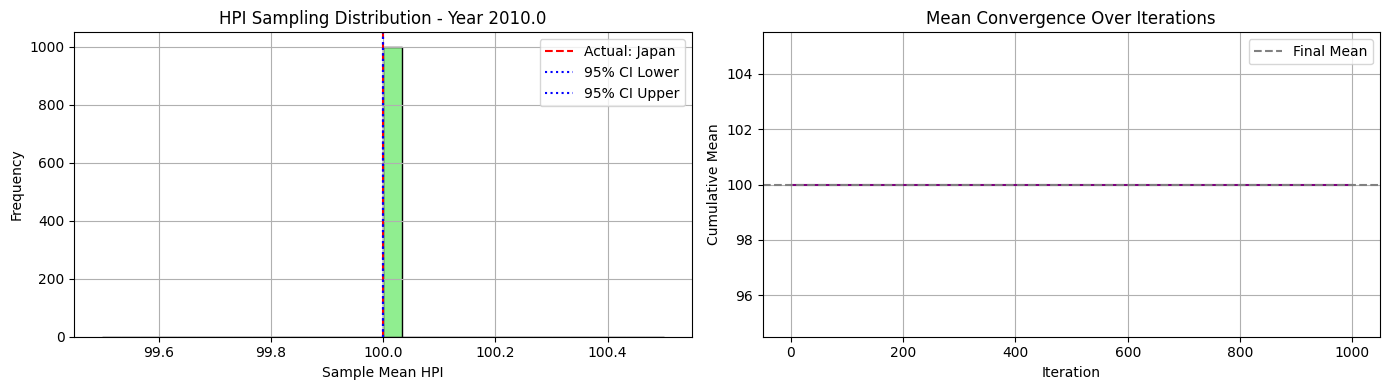


📅 Year 2011.0 - Available HPI values for sampling:
[110.42 110.42 107.89  96.56 105.8  105.57  94.49  97.62 105.23 104.26
  97.24]


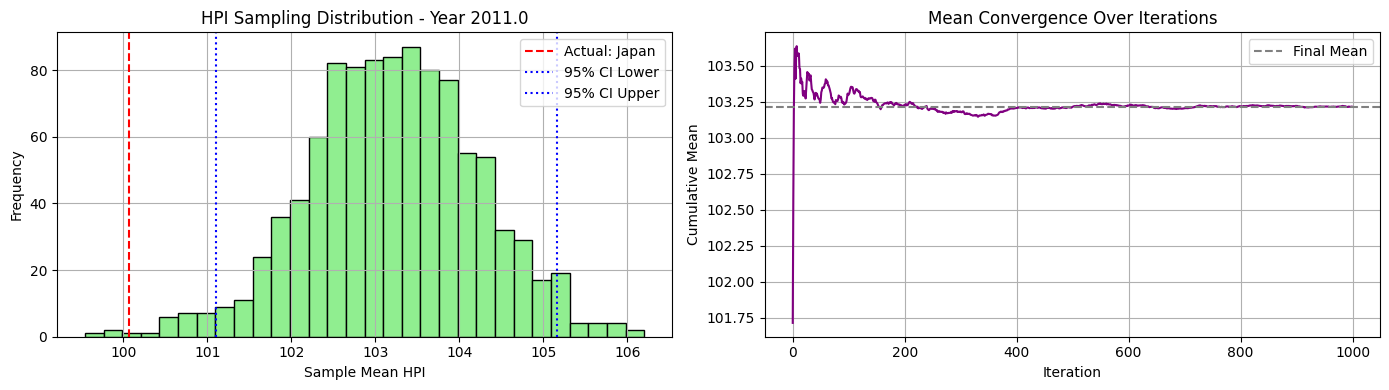


📅 Year 2012.0 - Available HPI values for sampling:
[118.79 118.79 118.79  92.98 109.17 114.94  91.1   95.68 108.25 107.63
 101.82]


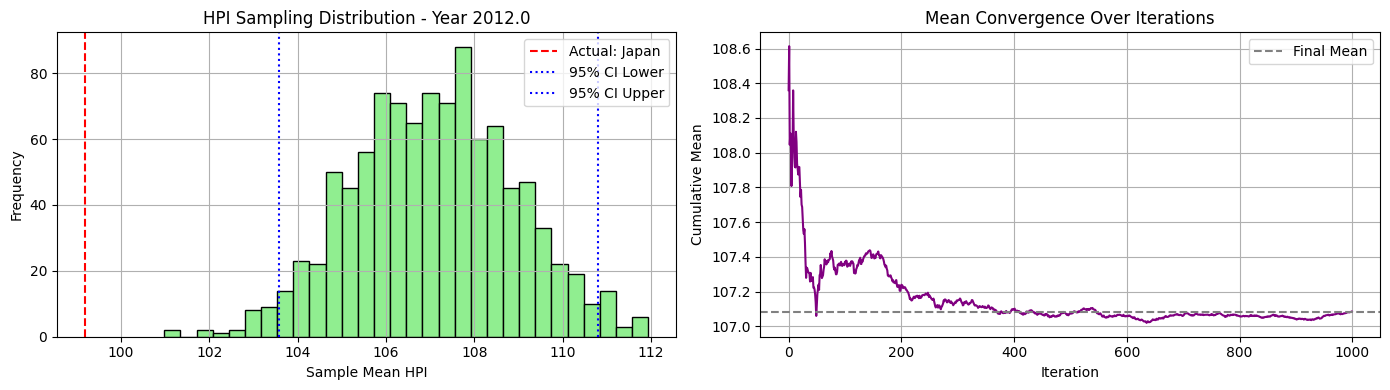


📅 Year 2013.0 - Available HPI values for sampling:
[130.06 130.06 130.06  90.58 114.75 127.86  94.32  90.62 107.8  115.99
 111.83]


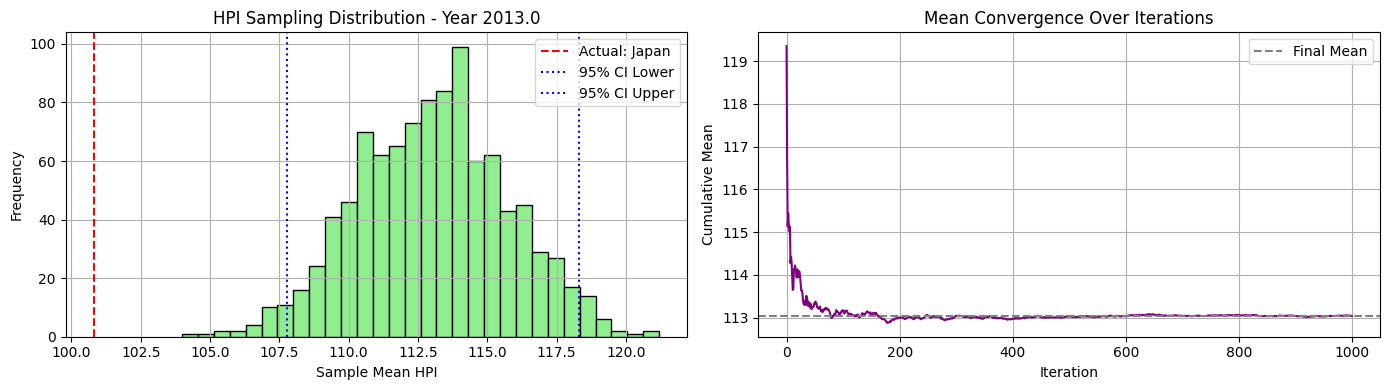


📅 Year 2014.0 - Available HPI values for sampling:
[146.41 146.41 140.75  94.37 119.64 142.76  95.84  95.77 109.43 127.07
 118.88]


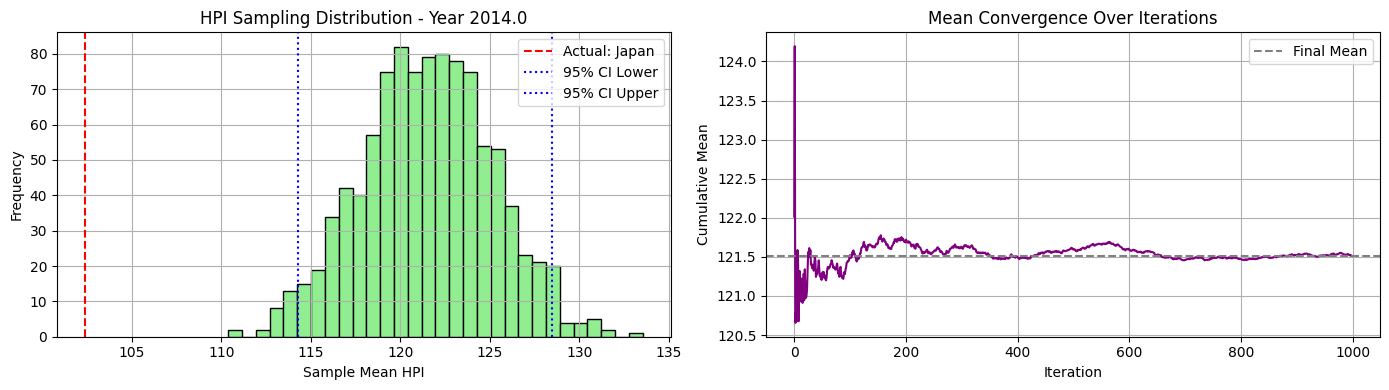


📅 Year 2015.0 - Available HPI values for sampling:
[156.16 156.46 152.93 106.75 129.39 156.46  97.    99.5  113.08 136.
 125.18]


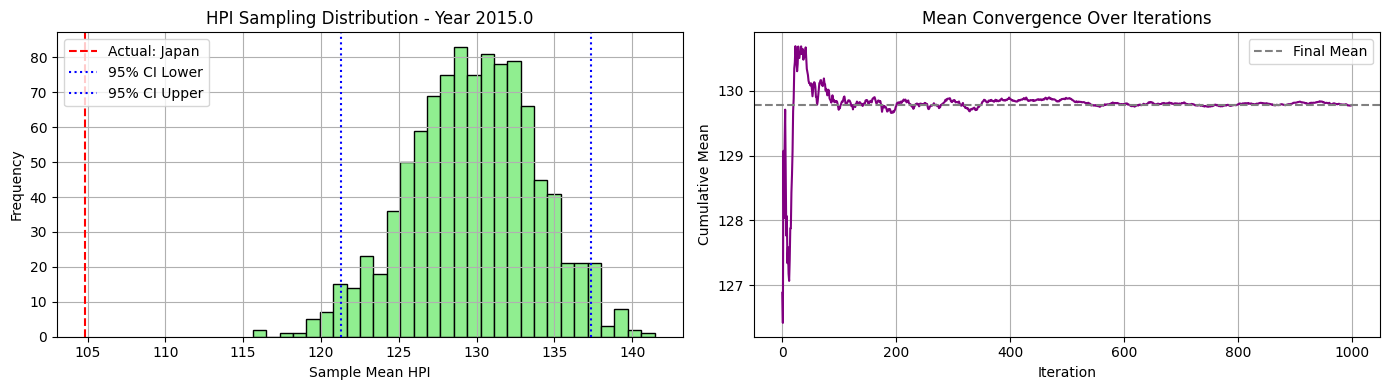


📅 Year 2016.0 - Available HPI values for sampling:
[151.94 164.18 164.18 121.03 138.82 164.18  91.86 110.62 116.09 142.4
 131.88]


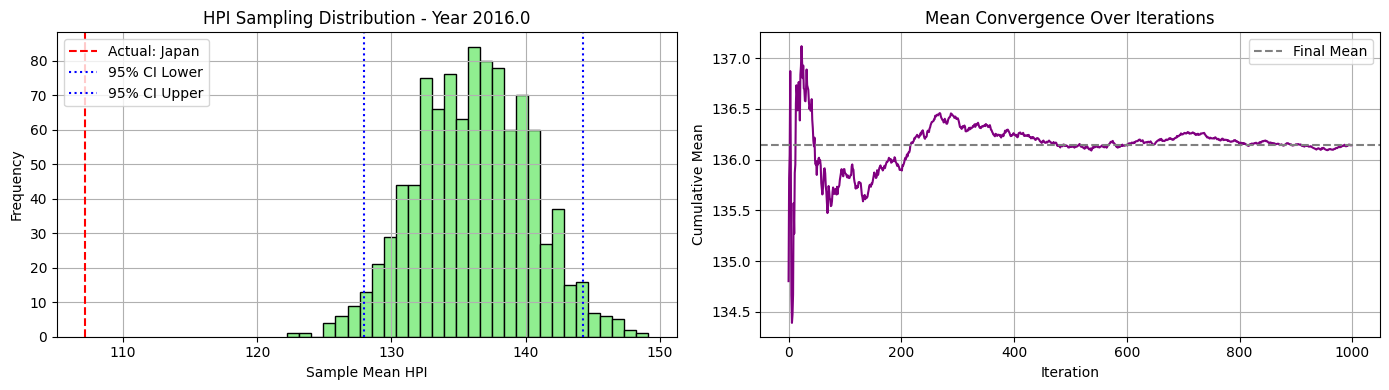


📅 Year 2017.0 - Available HPI values for sampling:
[149.02 178.56 178.56 135.84 149.69 178.56  88.54 115.3  117.6  146.48
 139.61]


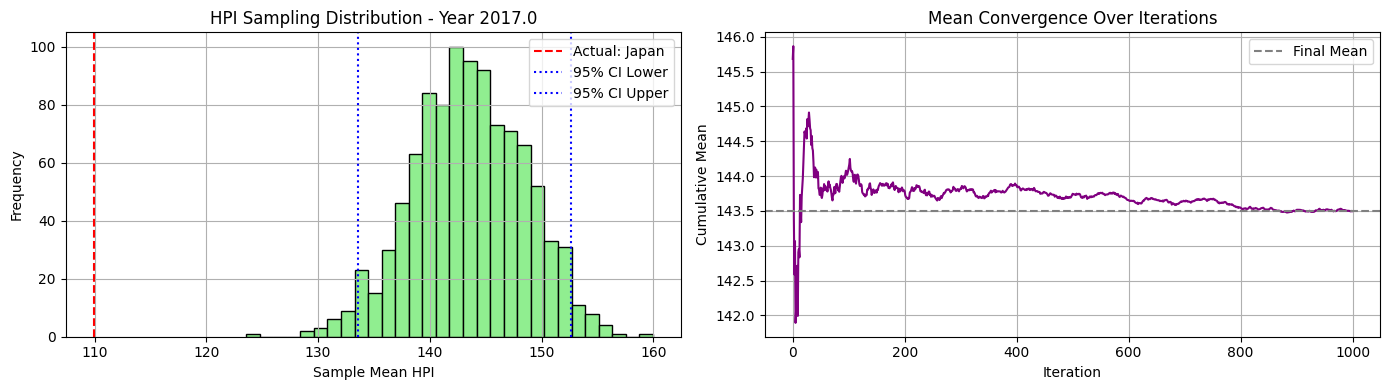


📅 Year 2018.0 - Available HPI values for sampling:
[149.81 183.82 183.82 155.3  162.97 183.82  90.72 123.06 120.22 153.9
 147.35]


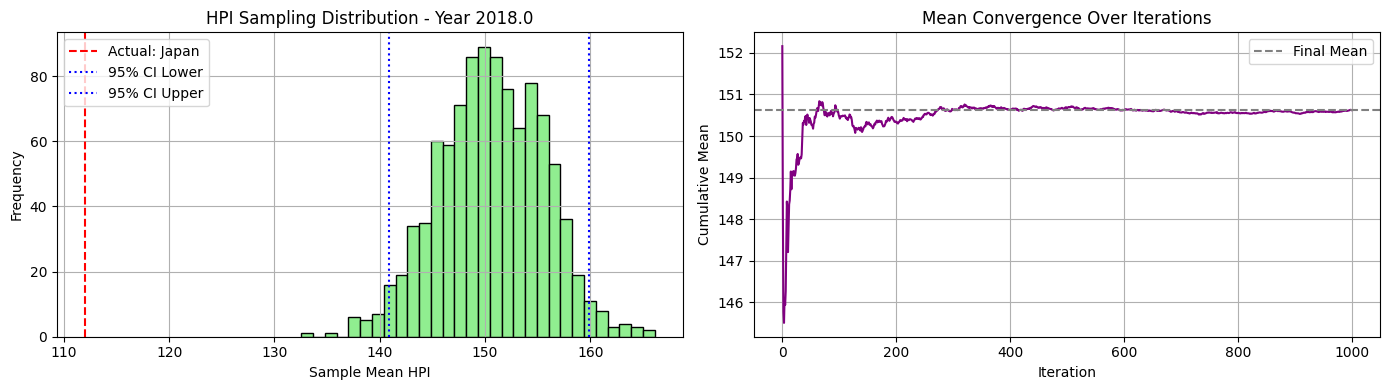


📅 Year 2019.0 - Available HPI values for sampling:
[155.06 195.98 195.98 181.64 176.92 195.26  97.25 135.77 121.93 155.1
 153.14]


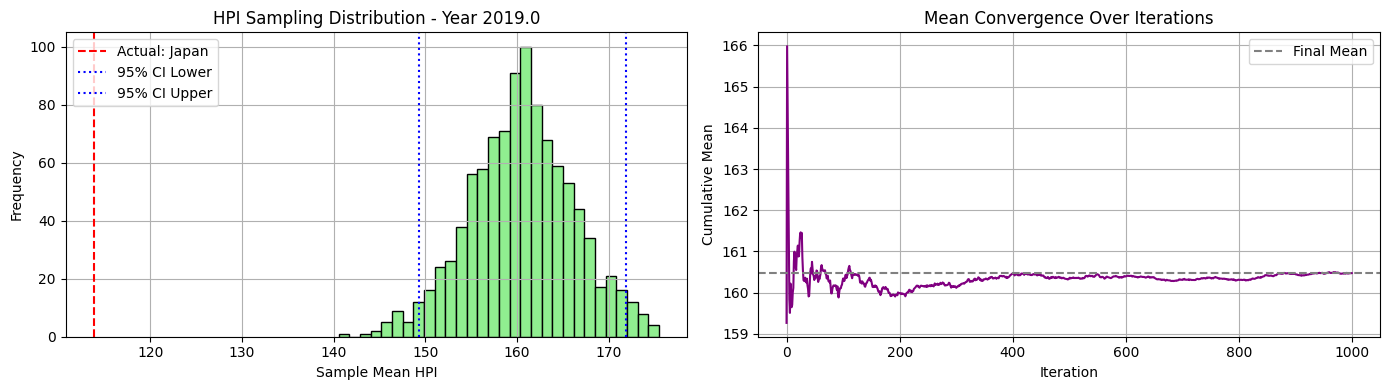


📅 Year 2020.0 - Available HPI values for sampling:
[166.92 203.12 203.12 190.63 187.18 203.12 106.71 149.28 126.56 160.6
 163.52]


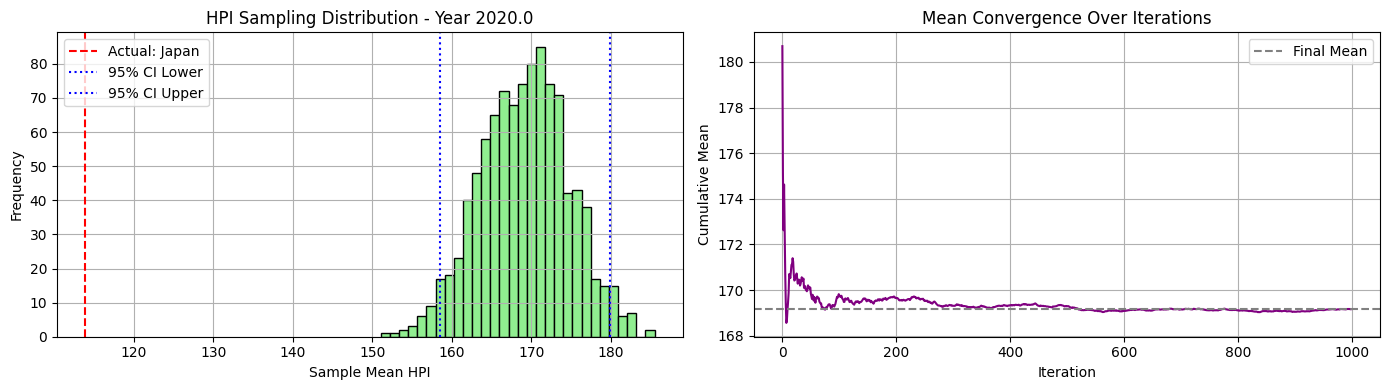


📅 Year 2021.0 - Available HPI values for sampling:
[180.02 222.1  214.9  222.1  201.94 211.74 121.41 166.04 143.73 164.23
 188.56]


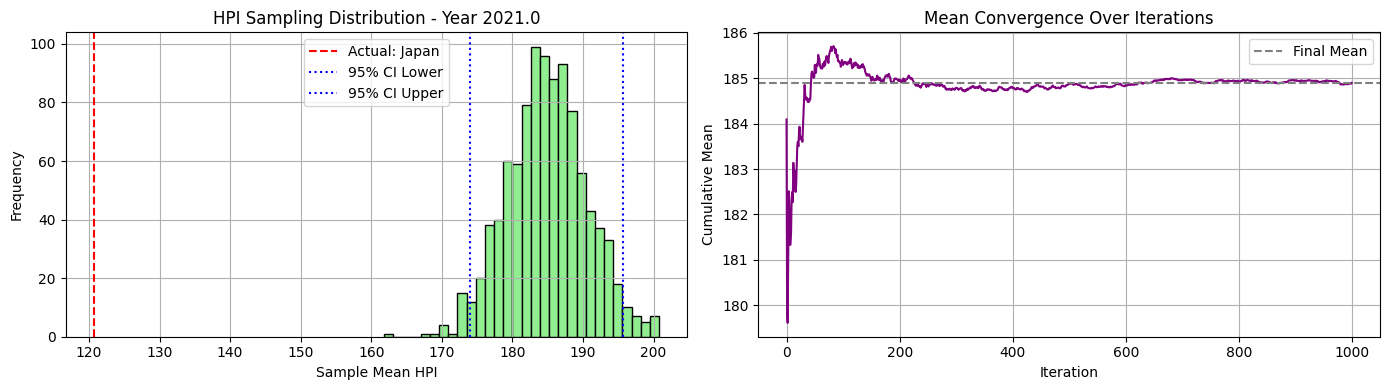


📅 Year 2022.0 - Available HPI values for sampling:
[185.16 249.69 230.   249.69 219.93 223.73 155.16 191.49 153.22 169.16
 213.  ]


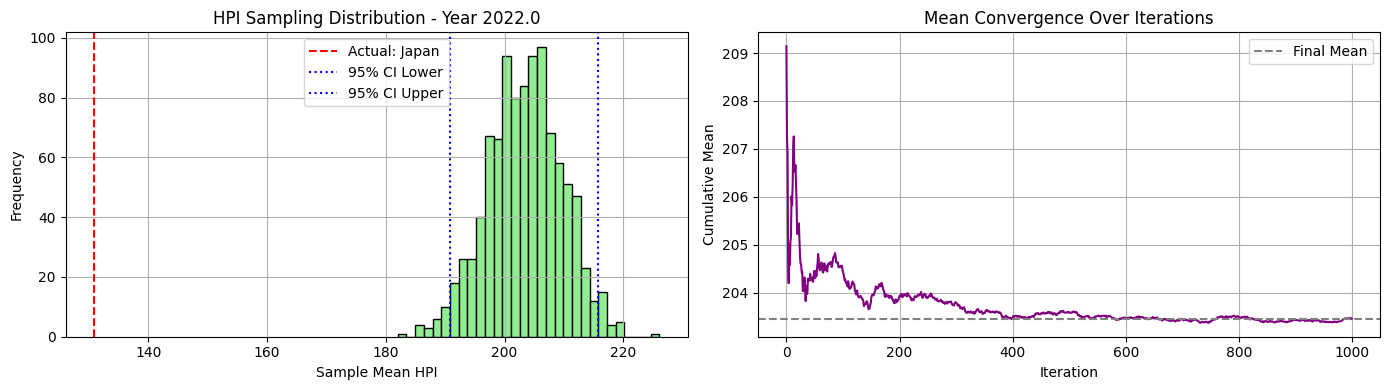


📅 Year 2023.0 - Available HPI values for sampling:
[191.27 254.38 245.75 254.38 243.89 248.04 157.88 209.99 143.99 174.79
 221.72]


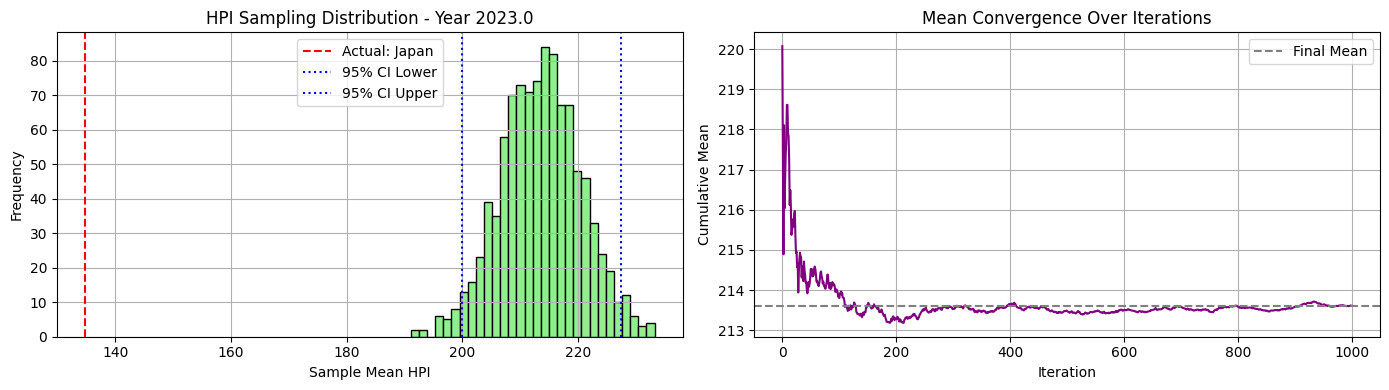


📅 Year 2024.0 - Available HPI values for sampling:
[203.78 279.12 269.02 279.12 266.38 256.03 186.66 220.7  142.46 178.06
 231.23]


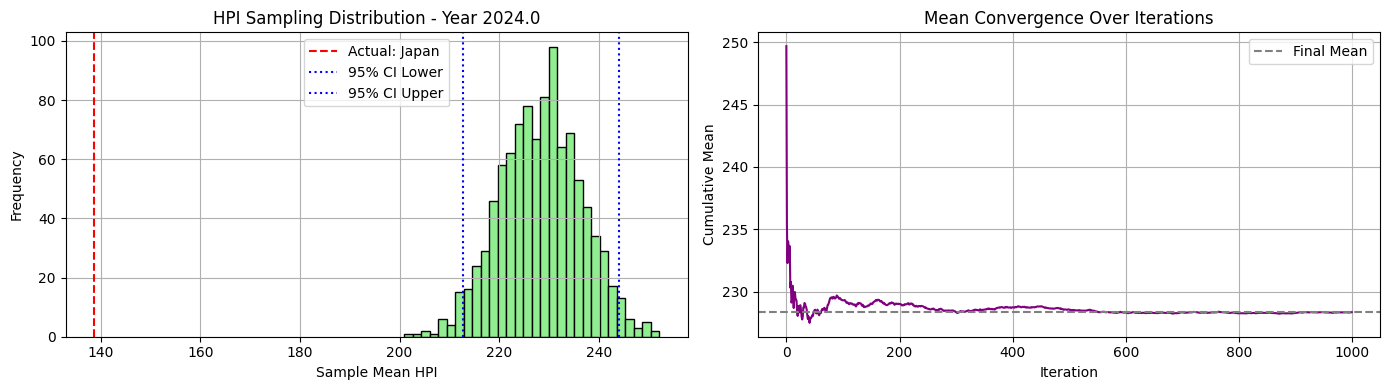

In [39]:
synthetic_c2_ni20_maxi500_h2_23_00, excluded_c2_ni20_maxi500_h2_23_00, actual_c2_ni20_maxi500_h2_23_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, c2_ni20_maxi500, cluster_id=0, seed=23)

🔍 Cluster 1 selected. Excluding country: Latvia
📊 Sampling from countries: ['Australia', 'Austria', 'Belgium', 'Bulgaria', 'Canada', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Iceland', 'Ireland', 'Israel', 'Italy', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New Zealand', 'Norway', 'Peru', 'Poland', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'United Kingdom']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100.]


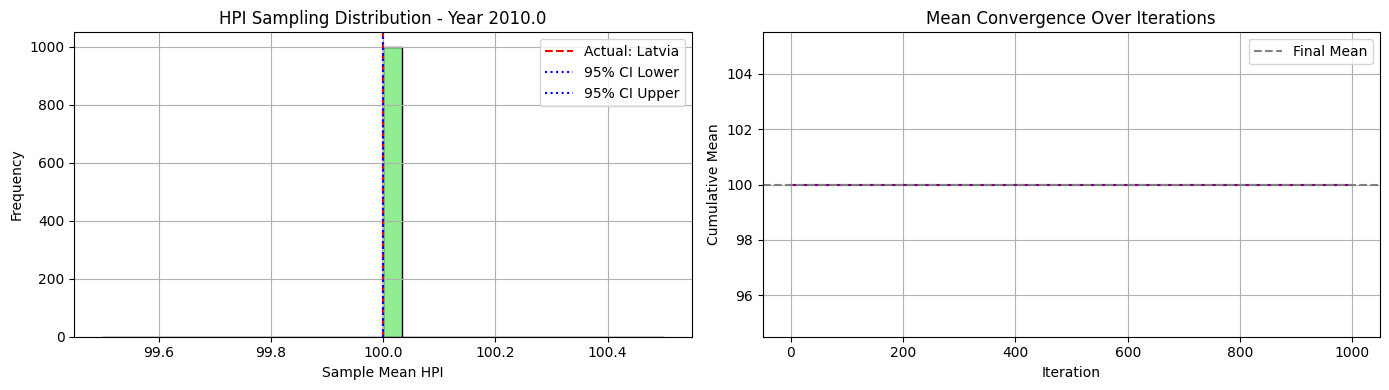


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 104.22 103.58  94.49 105.75 100.16  96.68 100.02  98.29 108.47
 103.17 105.69 102.42  94.53 105.5   94.49 110.42 101.36 106.6  103.68
 109.83  98.63  98.02 100.75 108.01 110.42 100.08  95.1   94.49 109.46
  98.46 102.72 103.59  94.49 102.58 107.51  98.54]


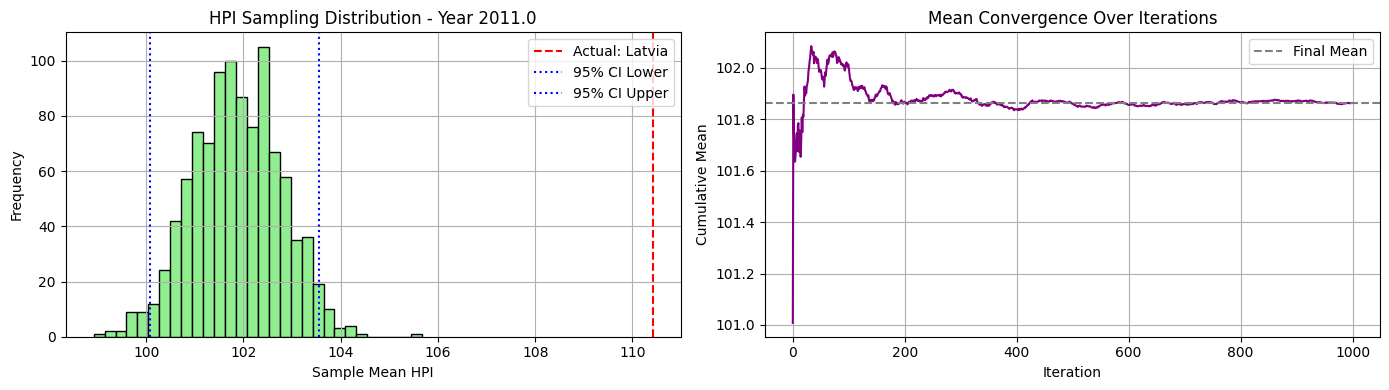


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 117.13 106.02  92.69 110.62  98.62  91.54  98.56  95.67 116.34
 105.64 105.11 105.48  88.37 112.38  88.37 114.1   98.77 106.36 108.03
 118.79 101.62  91.44 105.25 115.34 118.79  96.58  88.37  88.37 112.02
  95.73  95.63 108.41  88.37 103.86 113.72  98.92]


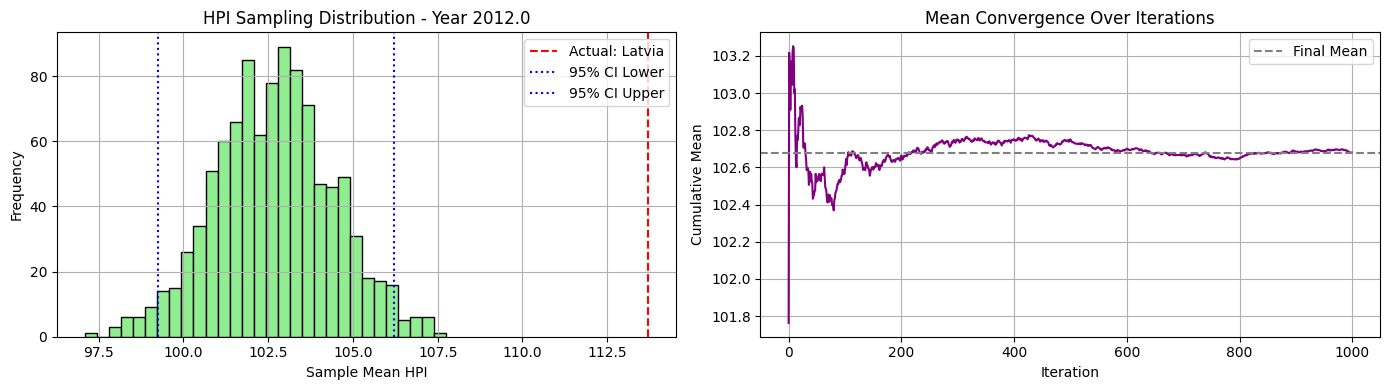


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 122.59 107.59  90.65 112.76  94.7   85.58  98.58  99.37 128.77
 106.87 103.13 108.68  85.58 119.18  85.58 124.45  92.38 107.65 113.42
 130.06 101.21  85.95 114.59 119.98 130.06  92.35  86.7   85.58 115.56
  96.53  90.62 115.41  85.58 109.22 118.3  101.46]


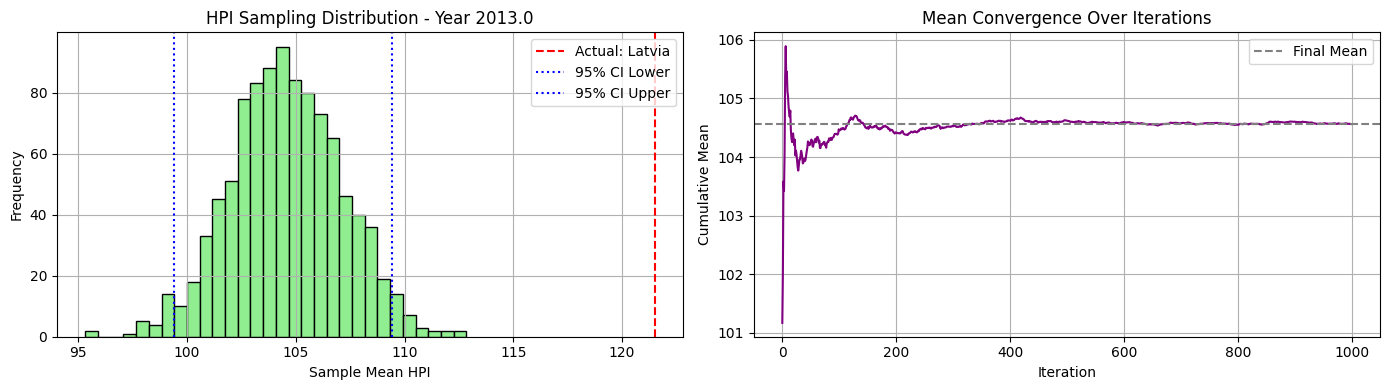


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 126.79 107.22  91.95 118.86  93.19  84.64 101.   103.12 146.41
 106.5  101.58 111.85  84.64 128.94  84.66 132.36  88.02 114.57 118.39
 146.41 103.79  86.66 122.03 123.24 146.41  93.27  90.38  84.64 112.25
  97.8   84.64 123.99  84.64 119.52 121.46 109.6 ]


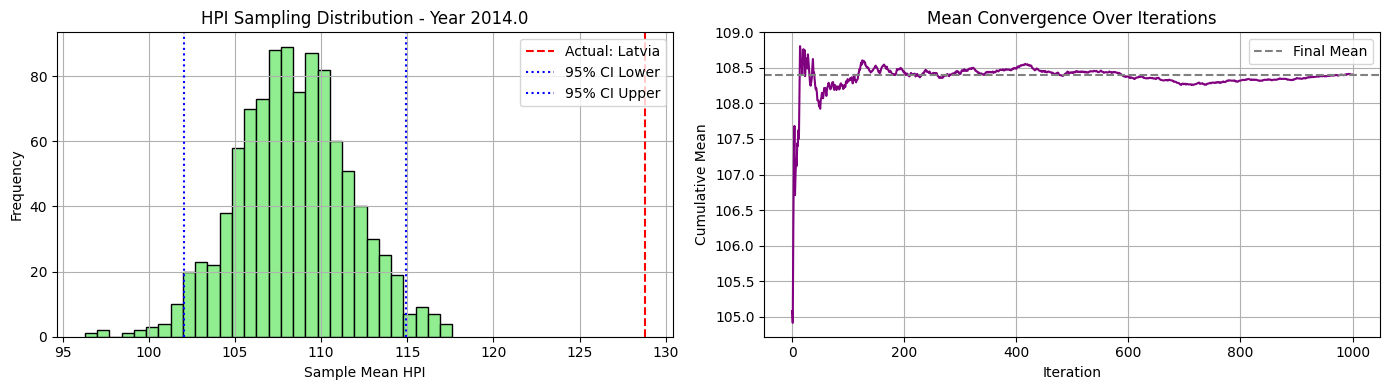


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 132.06 109.17  94.51 128.43  90.54  84.67 105.01 110.29 156.46
 106.5  100.22 117.12  84.67 139.74  94.36 140.12  84.67 118.76 124.78
 156.46 109.83  89.69 137.18 130.76 156.46  94.69  93.15  84.67 107.92
 103.    85.32 131.8   84.67 135.2  124.08 116.12]


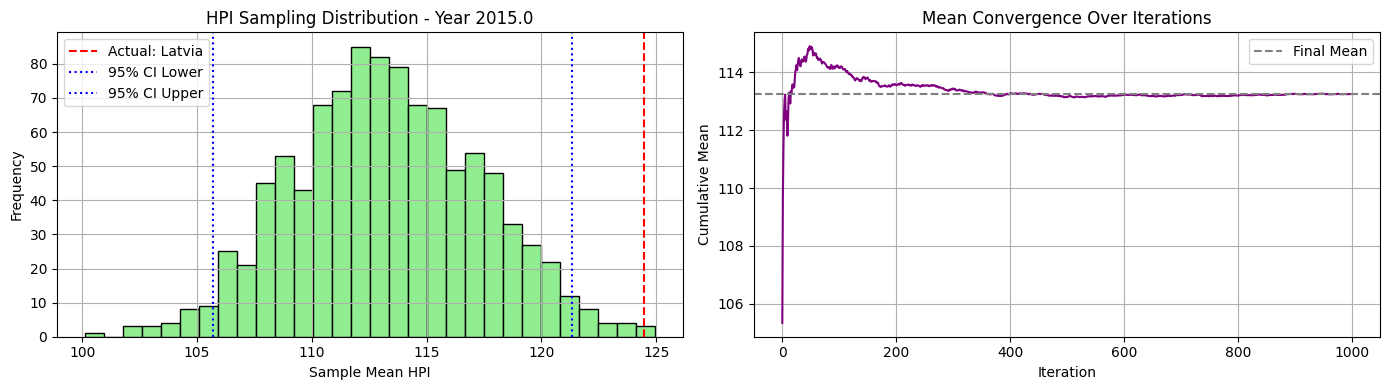


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 141.76 111.72 101.15 148.66  91.33  88.1  112.52 115.5  163.86
 107.86 101.25 125.93  88.1  154.59 101.42 150.56  88.1  125.16 132.28
 164.18 115.82  94.43 156.62 139.95 164.18  96.44  99.78  88.91 104.55
 109.87  88.1  138.22  88.1  146.34 124.32 124.27]


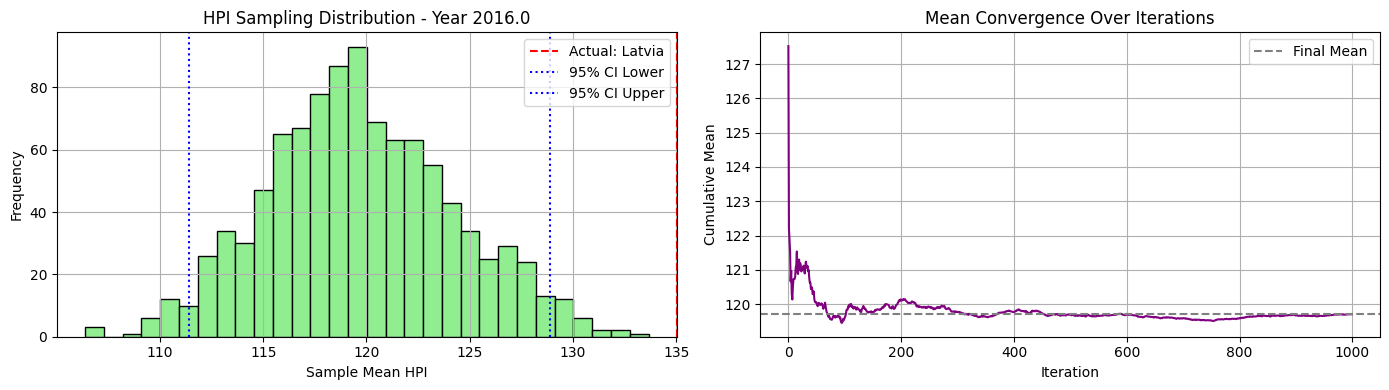


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 147.08 115.66 109.91 172.3   94.84  88.54 125.7  120.63 172.91
 109.02 104.46 133.62  88.54 178.56 112.44 156.44  88.54 136.34 139.69
 178.56 121.94 102.06 166.8  146.91 168.   100.16 108.99  93.93 103.4
 116.3   95.38 143.94  88.54 156.06 125.42 129.93]


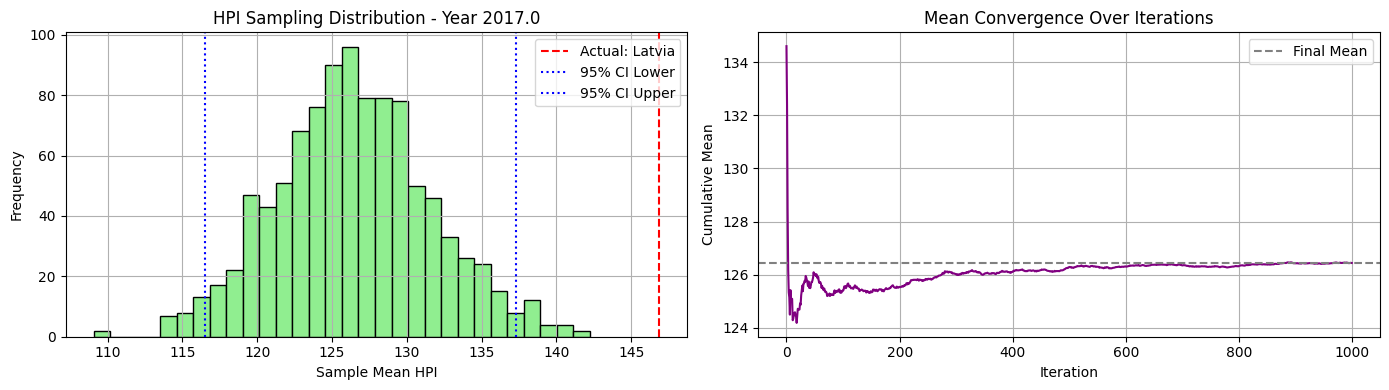


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  157.24 119.16 117.15 178.24 100.59  90.72 136.52 126.31 183.13
 110.06 107.52 142.52  90.72 183.82 123.96 155.14  90.72 146.29 149.55
 183.82 129.02 111.57 172.8  149.04 168.42 106.75 120.19  99.37 111.46
 124.97 103.7  148.96  90.72 154.6  129.16 134.04]


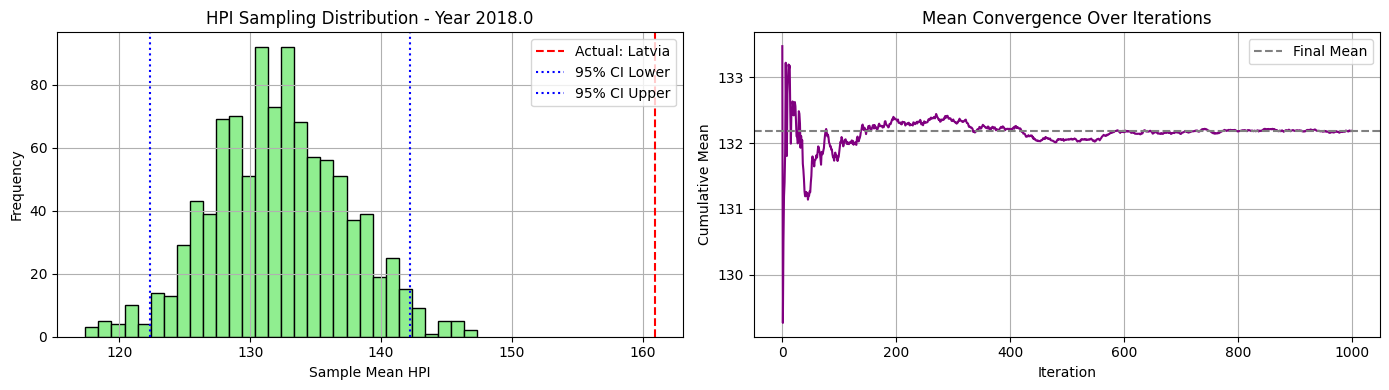


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 163.43 123.62 124.2  179.4  109.64  97.25 149.02 129.62 195.98
 110.52 111.1  150.75  97.25 195.98 126.85 158.06  97.25 156.3  164.68
 195.98 136.9  119.62 178.19 152.73 172.03 116.01 132.16 102.72 113.98
 136.39 110.65 152.69  97.25 158.44 133.99 135.37]


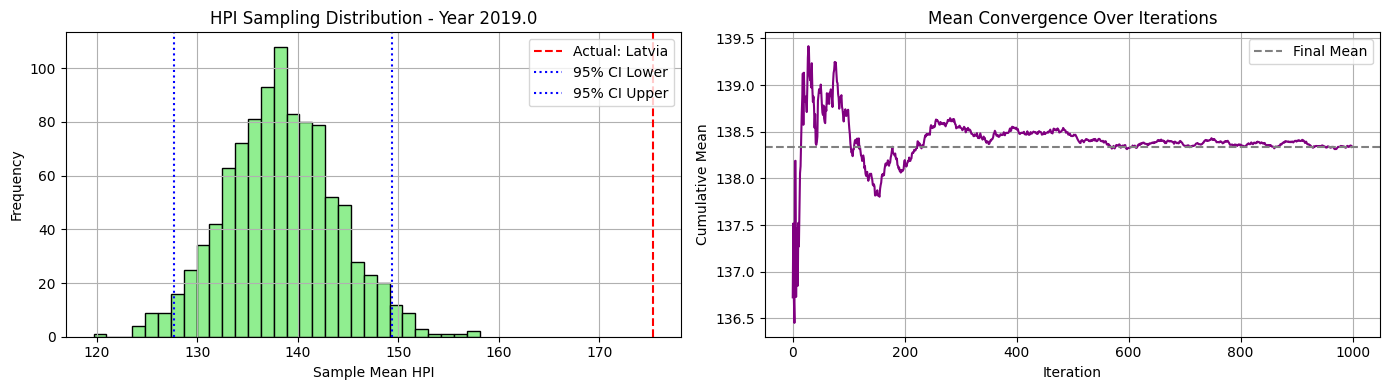


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 174.92 128.92 129.87 190.73 118.06 100.19 161.56 136.24 203.12
 112.49 116.89 162.48 100.19 203.12 127.24 162.9  100.19 167.66 188.57
 198.37 141.54 129.21 196.31 159.24 173.67 128.18 143.75 107.53 115.8
 149.36 115.74 156.31 100.19 165.09 137.31 139.24]


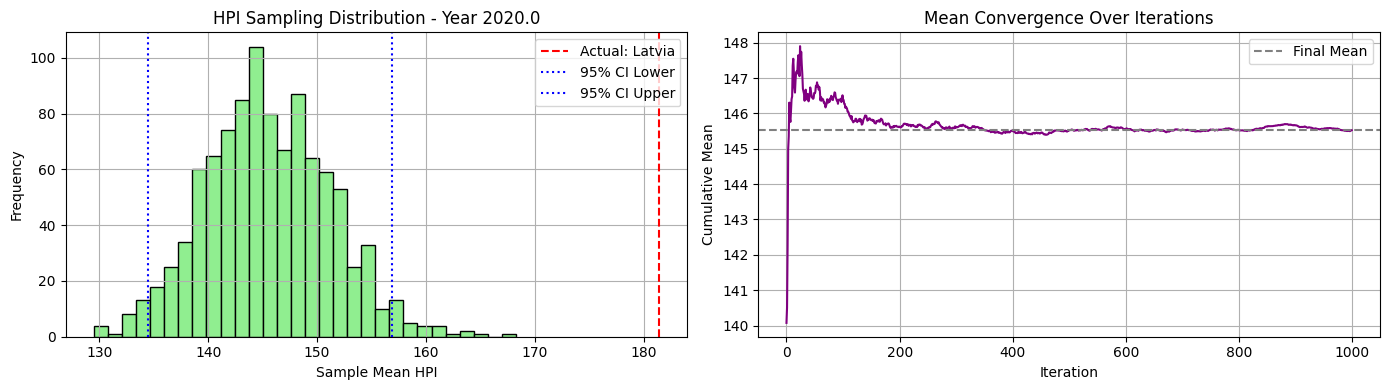


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 195.48 137.52 141.14 214.88 126.64 102.55 193.46 152.2  222.1
 117.62 124.38 181.28 102.55 222.1  137.77 176.65 102.55 194.58 214.81
 200.69 148.74 147.93 222.1  175.91 173.6  139.92 157.27 112.34 125.04
 158.94 129.1  166.82 102.55 181.79 145.16 150.58]


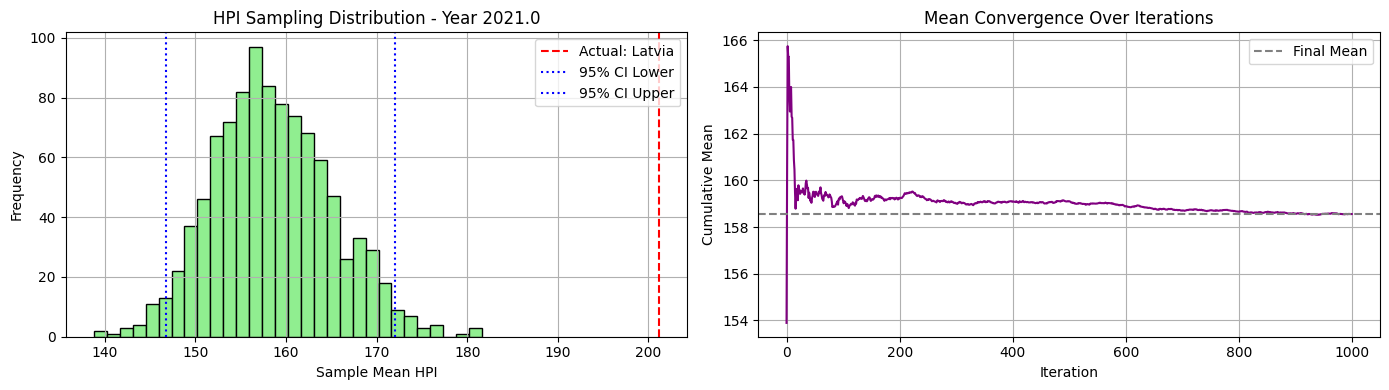


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 215.62 145.12 160.59 235.32 145.44 105.52 226.15 151.49 249.69
 118.98 132.1  190.42 105.52 249.69 154.73 207.16 105.52 231.64 235.34
 207.75 158.62 167.57 249.69 185.13 172.65 156.43 177.14 120.29 137.74
 180.7  148.16 174.03 105.52 188.27 154.42 164.55]


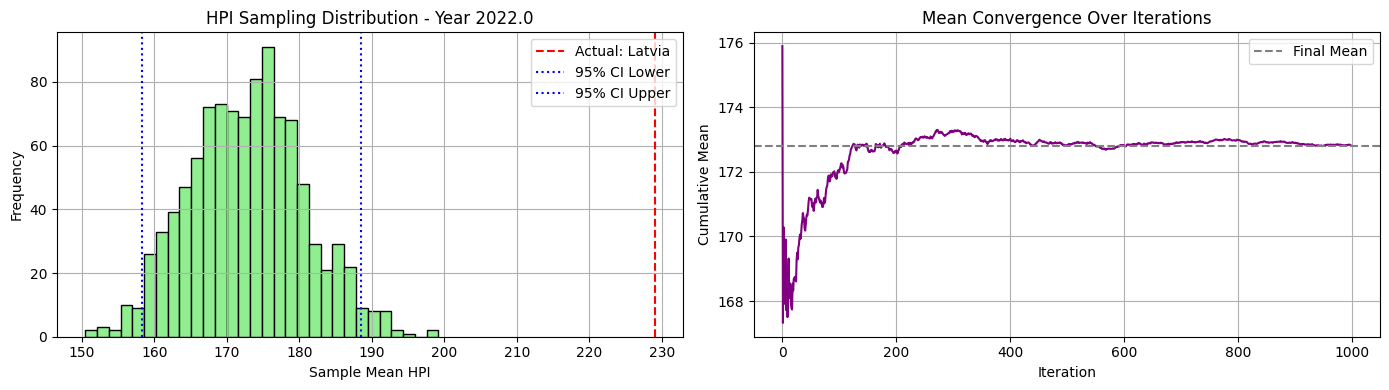


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 212.08 148.52 176.43 221.05 162.82 109.76 222.4  151.24 254.38
 112.27 131.52 174.25 109.76 254.38 159.48 214.23 109.76 254.38 214.
 216.19 168.5  164.36 233.54 184.12 175.16 170.23 191.66 124.06 148.01
 180.36 158.88 176.62 109.76 178.36 157.81 165.  ]


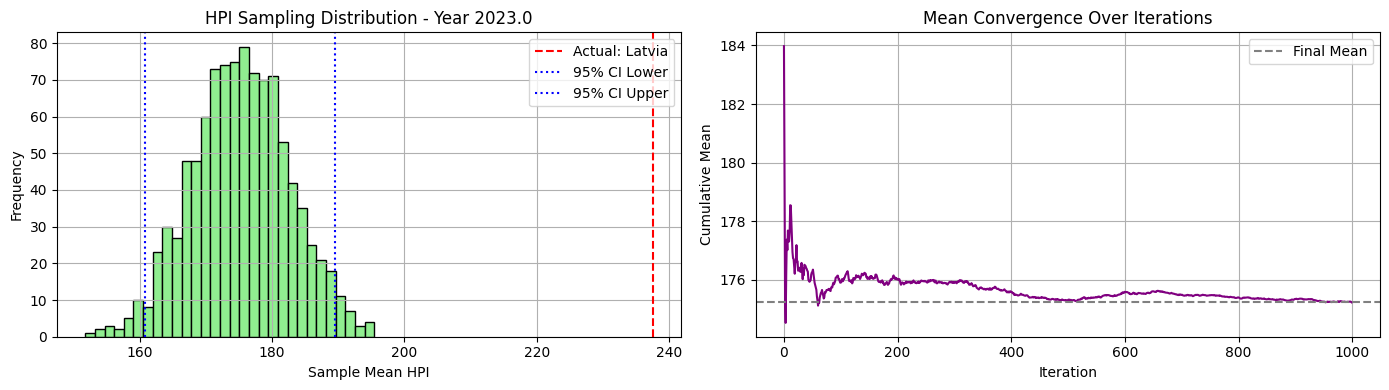


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 207.62 153.31 205.53 217.35 179.7  108.31 233.42 156.73 279.12
 108.31 126.68 171.5  108.31 279.12 173.07 224.54 108.31 279.12 202.74
 225.06 179.35 177.7  233.68 189.05 175.38 195.72 209.06 130.34 155.12
 187.15 170.56 178.1  119.1  178.49 160.56 166.38]


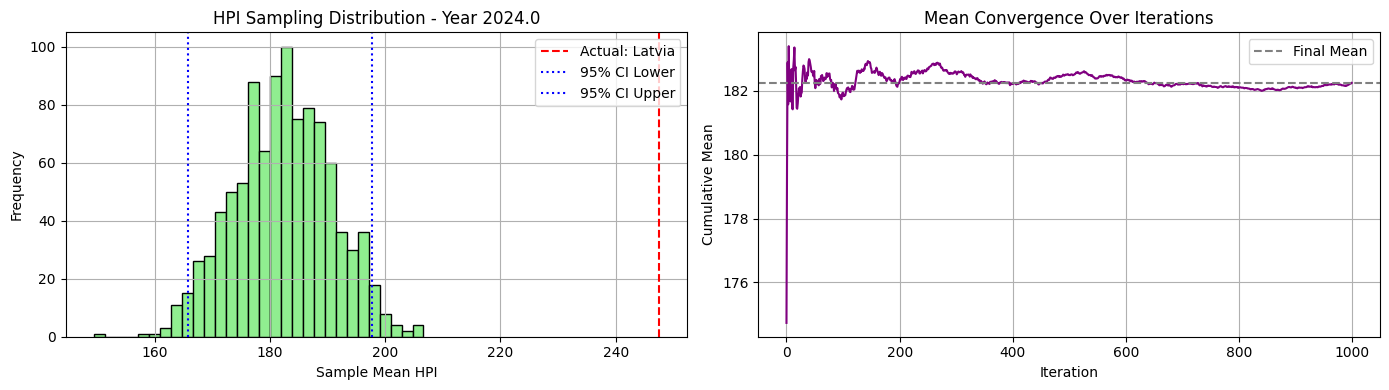

In [40]:
synthetic_c2_ni20_maxi500_h2_23_01, excluded_c2_ni20_maxi500_h2_23_01, actual_c2_ni20_maxi500_h2_23_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, c2_ni20_maxi500, cluster_id=1, seed=23)

### Sampling experiment with seed 32

🔍 Cluster 0 selected. Excluding country: Chile
📊 Sampling from countries: ['Brazil', 'Colombia', 'Hungary', 'Japan', 'Mexico', 'Philippines', 'Russia', 'Serbia', 'South Korea', 'Thailand', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


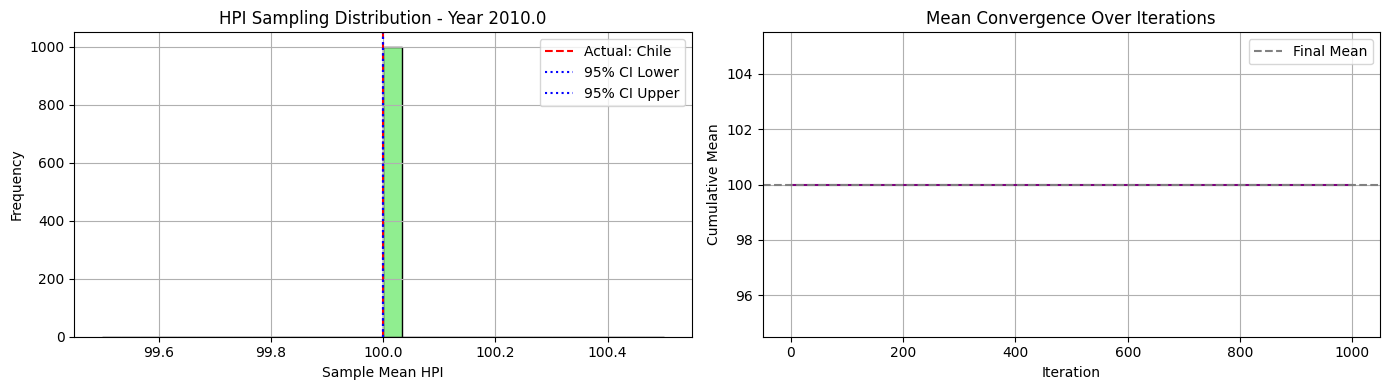


📅 Year 2011.0 - Available HPI values for sampling:
[110.42 107.89  96.56 100.07 105.8  105.57  94.49  97.62 105.23 104.26
  97.24]


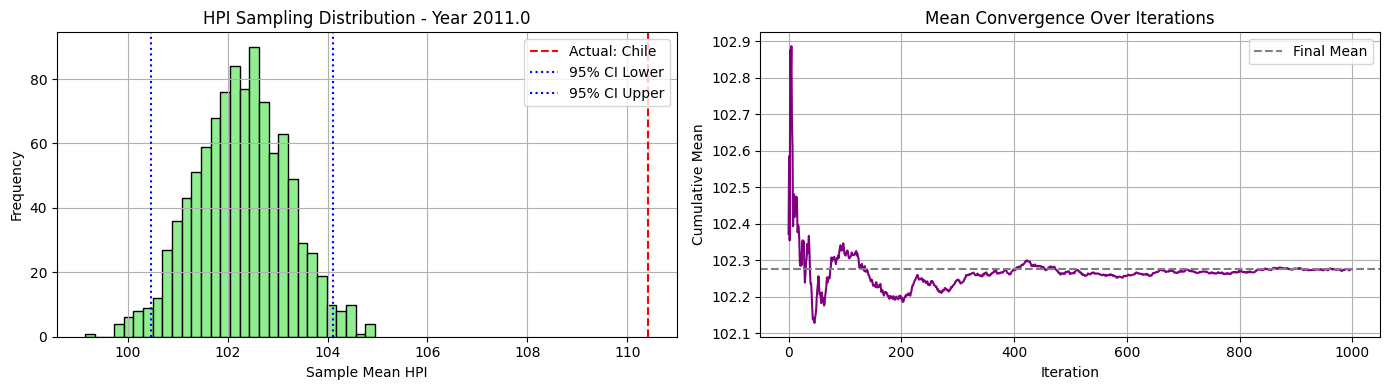


📅 Year 2012.0 - Available HPI values for sampling:
[118.79 118.79  92.98  99.19 109.17 114.94  91.1   95.68 108.25 107.63
 101.82]


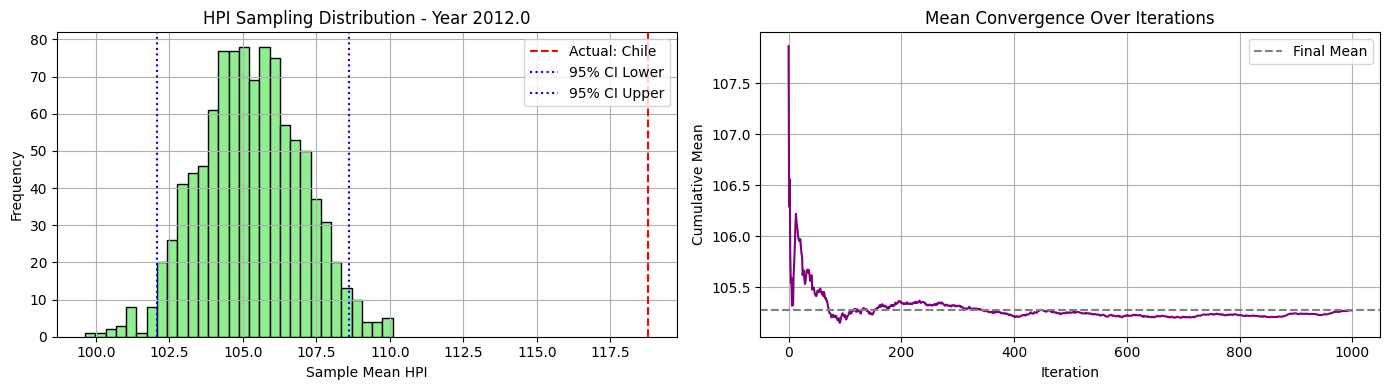


📅 Year 2013.0 - Available HPI values for sampling:
[130.06 130.06  90.58 100.81 114.75 127.86  94.32  90.62 107.8  115.99
 111.83]


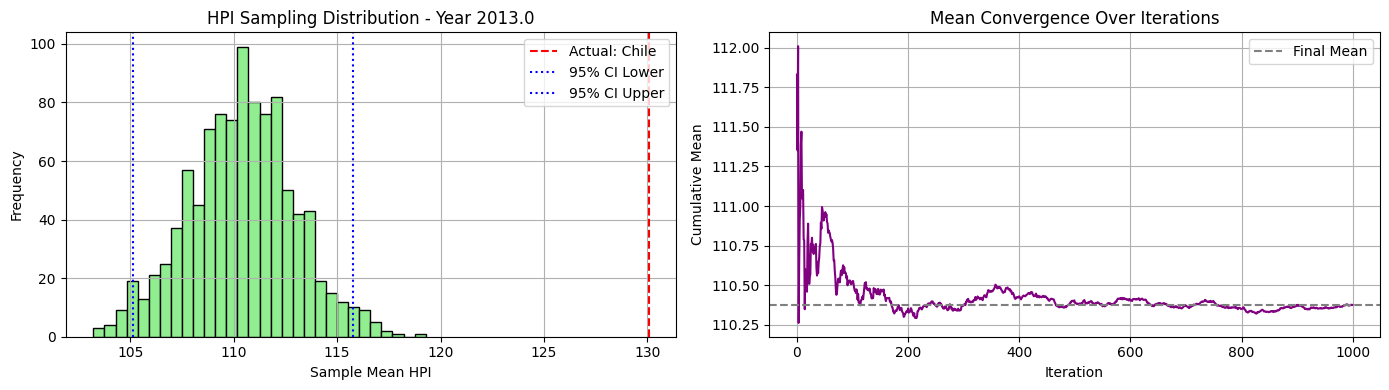


📅 Year 2014.0 - Available HPI values for sampling:
[146.41 140.75  94.37 102.38 119.64 142.76  95.84  95.77 109.43 127.07
 118.88]


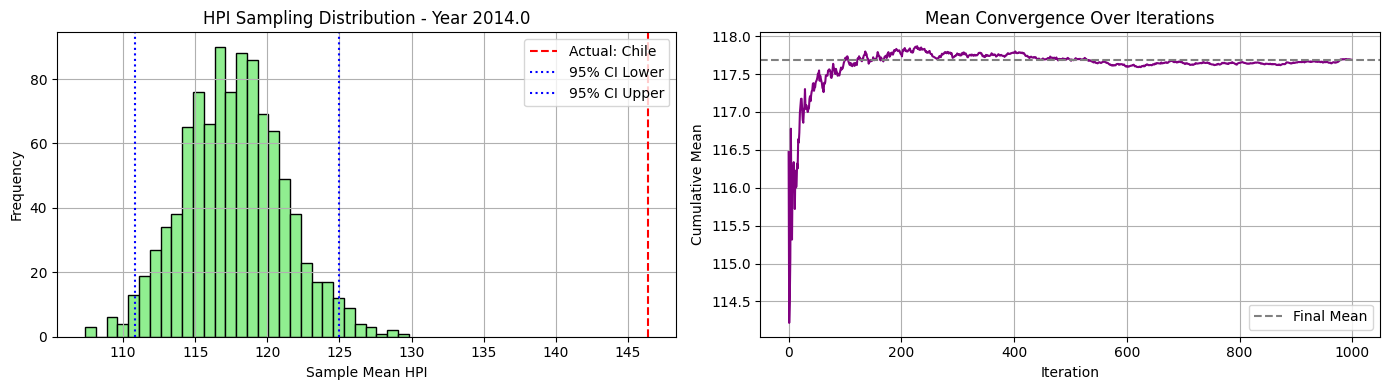


📅 Year 2015.0 - Available HPI values for sampling:
[156.16 152.93 106.75 104.86 129.39 156.46  97.    99.5  113.08 136.
 125.18]


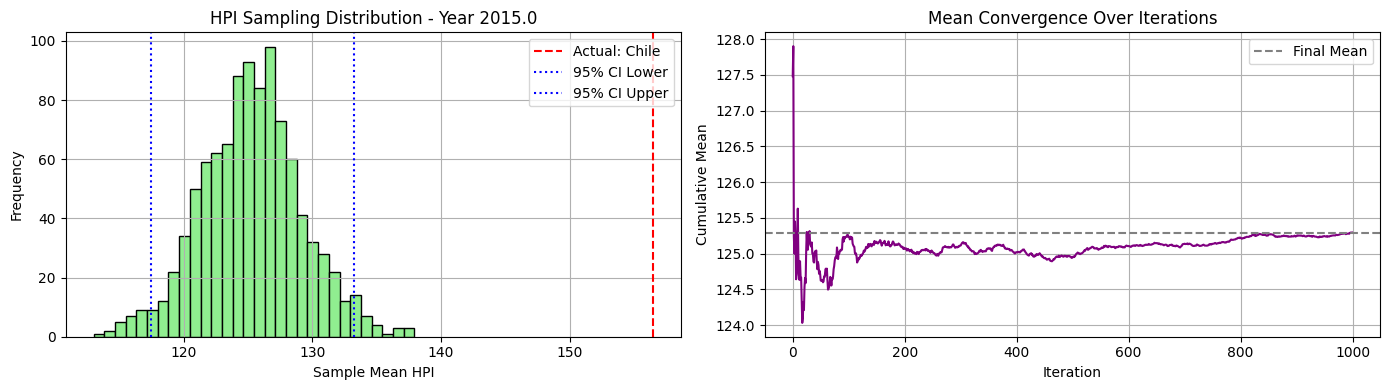


📅 Year 2016.0 - Available HPI values for sampling:
[151.94 164.18 121.03 107.18 138.82 164.18  91.86 110.62 116.09 142.4
 131.88]


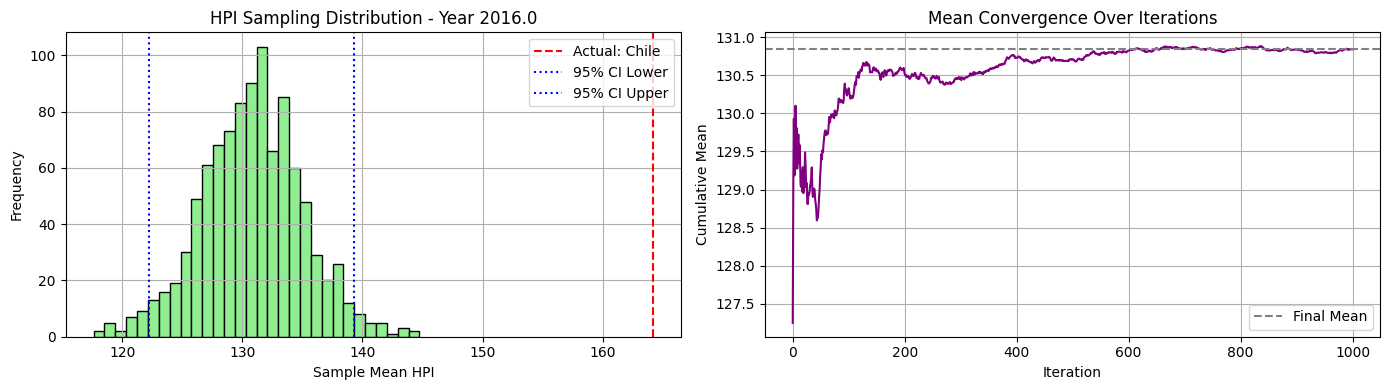


📅 Year 2017.0 - Available HPI values for sampling:
[149.02 178.56 135.84 109.91 149.69 178.56  88.54 115.3  117.6  146.48
 139.61]


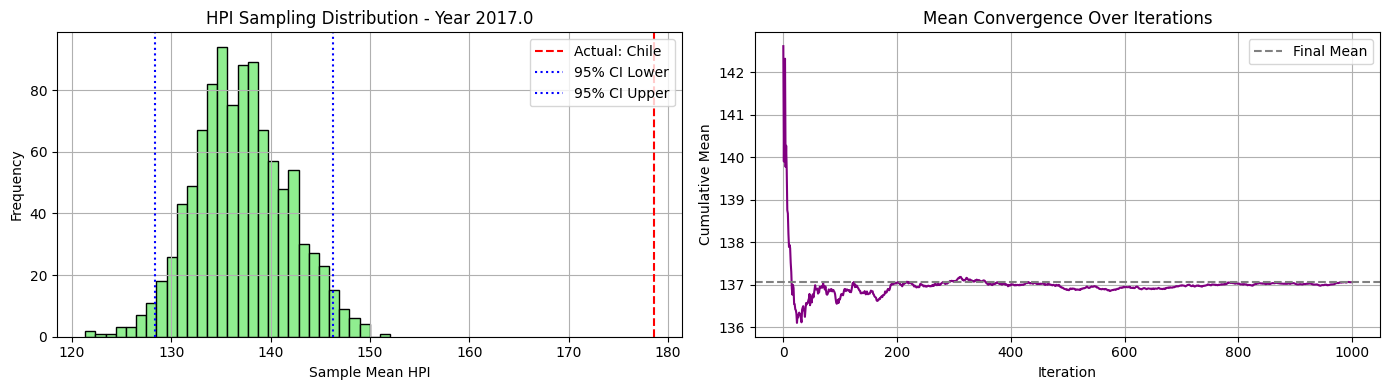


📅 Year 2018.0 - Available HPI values for sampling:
[149.81 183.82 155.3  112.04 162.97 183.82  90.72 123.06 120.22 153.9
 147.35]


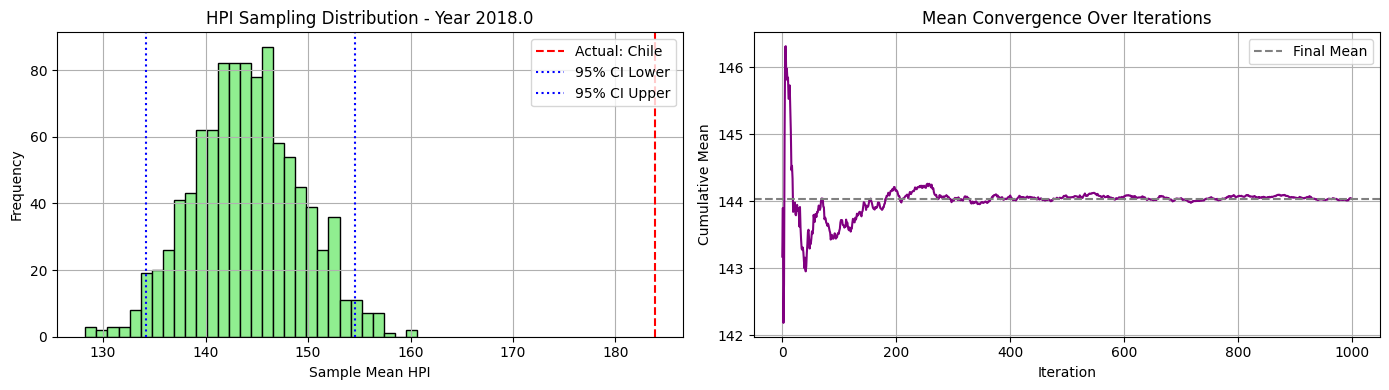


📅 Year 2019.0 - Available HPI values for sampling:
[155.06 195.98 181.64 113.84 176.92 195.26  97.25 135.77 121.93 155.1
 153.14]


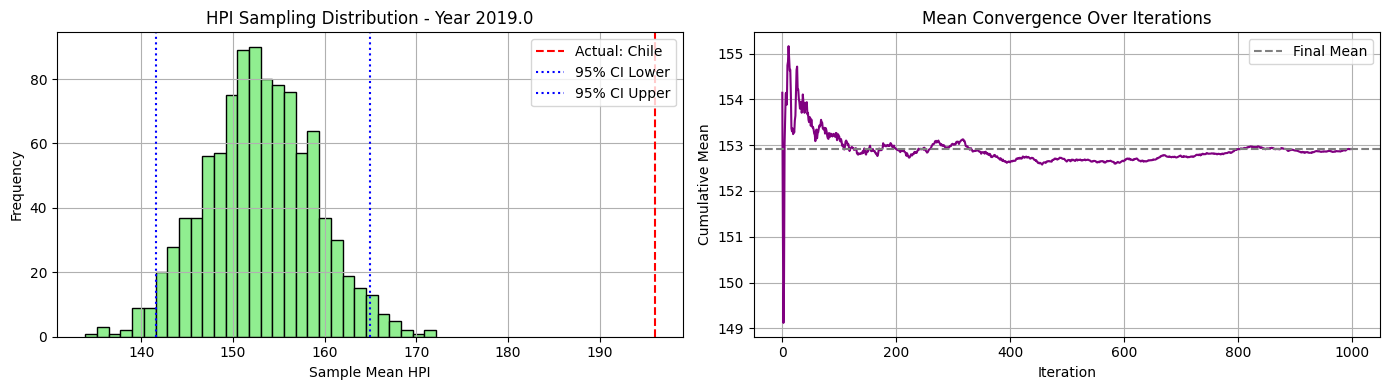


📅 Year 2020.0 - Available HPI values for sampling:
[166.92 203.12 190.63 113.93 187.18 203.12 106.71 149.28 126.56 160.6
 163.52]


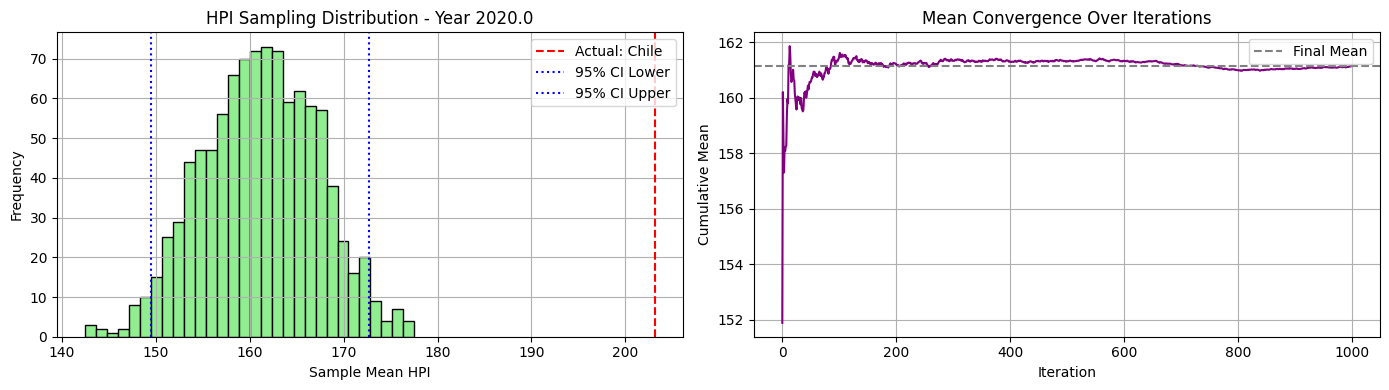


📅 Year 2021.0 - Available HPI values for sampling:
[180.02 214.9  222.1  120.7  201.94 211.74 121.41 166.04 143.73 164.23
 188.56]


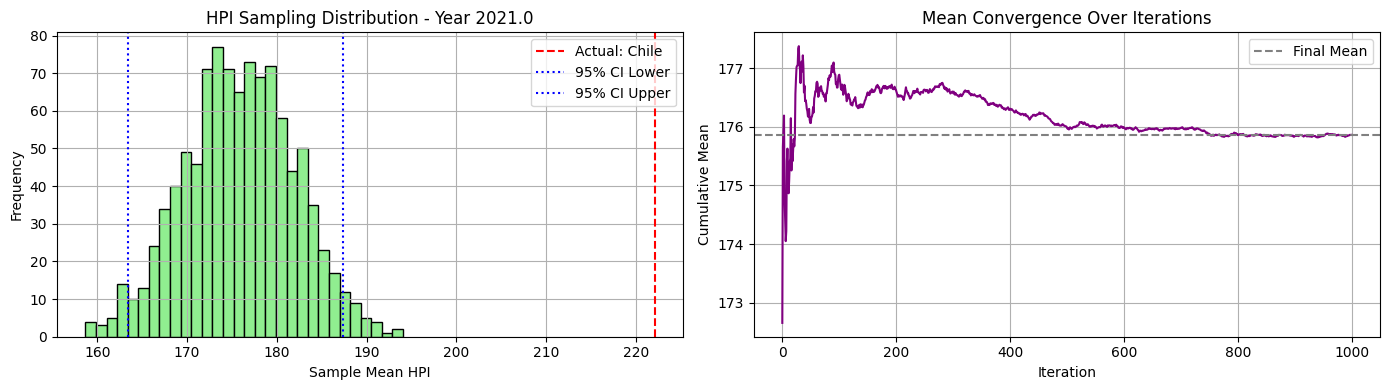


📅 Year 2022.0 - Available HPI values for sampling:
[185.16 230.   249.69 130.84 219.93 223.73 155.16 191.49 153.22 169.16
 213.  ]


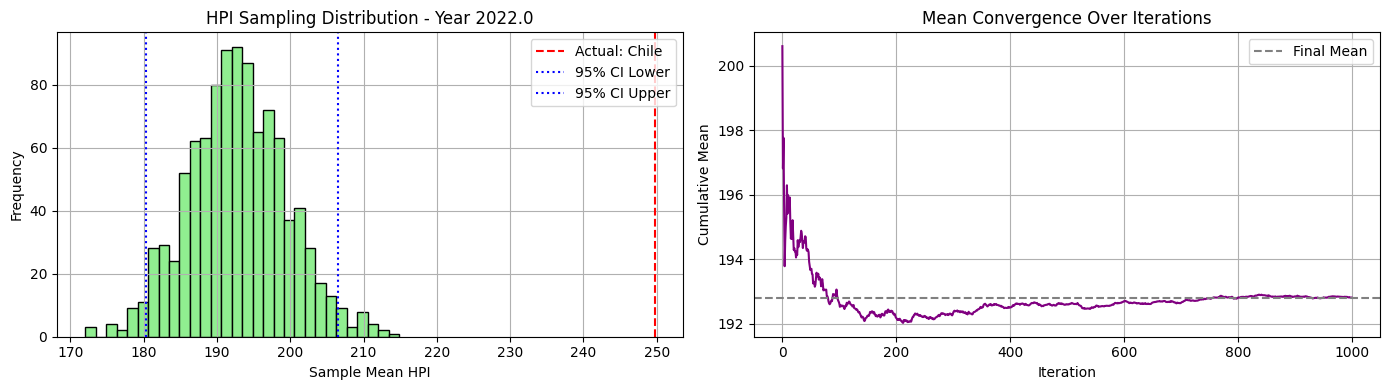


📅 Year 2023.0 - Available HPI values for sampling:
[191.27 245.75 254.38 134.8  243.89 248.04 157.88 209.99 143.99 174.79
 221.72]


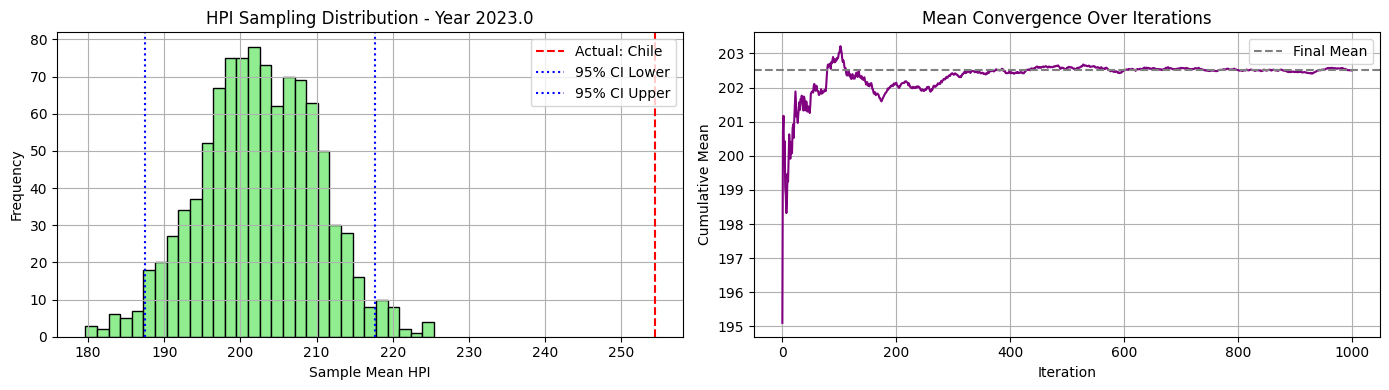


📅 Year 2024.0 - Available HPI values for sampling:
[203.78 269.02 279.12 138.61 266.38 256.03 186.66 220.7  142.46 178.06
 231.23]


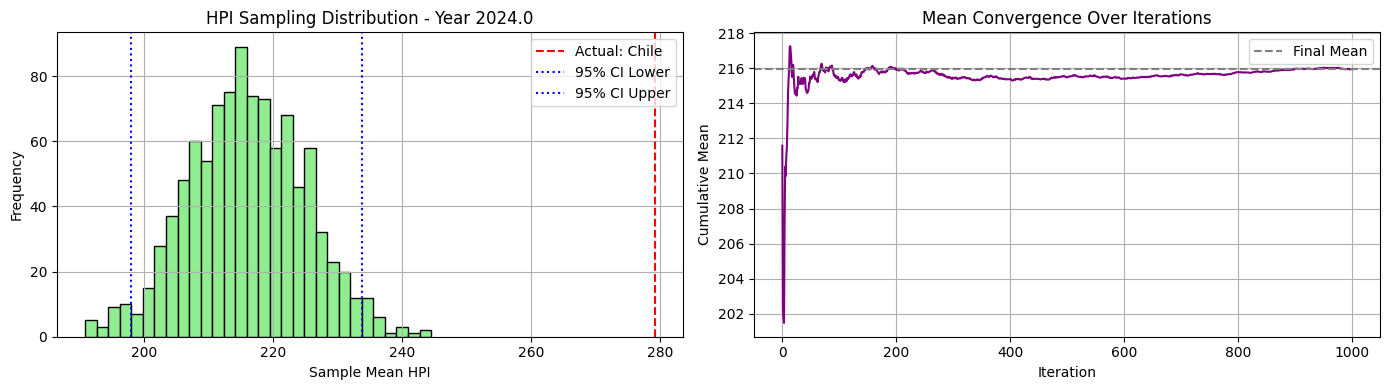

In [41]:
synthetic_c2_ni20_maxi500_h2_32_00, excluded_c2_ni20_maxi500_h2_32_00, actual_c2_ni20_maxi500_h2_32_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, c2_ni20_maxi500, cluster_id=0, seed=32)

🔍 Cluster 1 selected. Excluding country: Canada
📊 Sampling from countries: ['Australia', 'Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Iceland', 'Ireland', 'Israel', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New Zealand', 'Norway', 'Peru', 'Poland', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'United Kingdom']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100.]


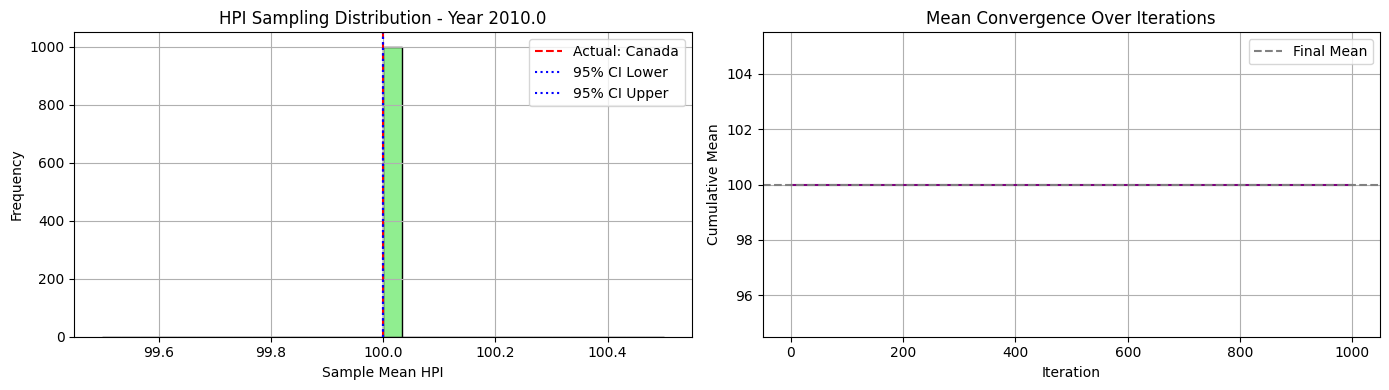


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 104.22 103.58  94.49 100.16  96.68 100.02  98.29 108.47 103.17
 105.69 102.42  94.53 105.5   94.49 110.42 101.36 110.42 106.6  103.68
 109.83  98.63  98.02 100.75 108.01 110.42 100.08  95.1   94.49 109.46
  98.46 102.72 103.59  94.49 102.58 107.51  98.54]


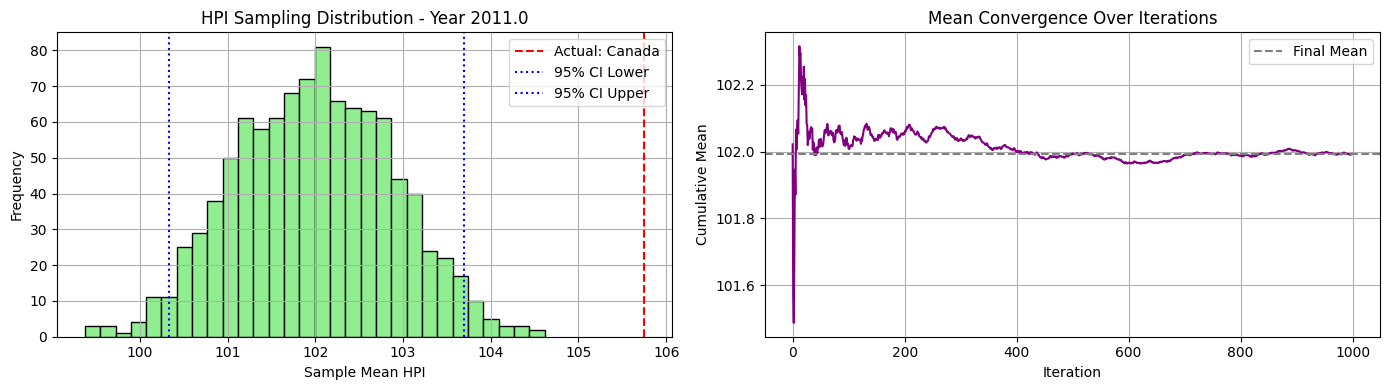


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 117.13 106.02  92.69  98.62  91.54  98.56  95.67 116.34 105.64
 105.11 105.48  88.37 112.38  88.37 114.1   98.77 113.71 106.36 108.03
 118.79 101.62  91.44 105.25 115.34 118.79  96.58  88.37  88.37 112.02
  95.73  95.63 108.41  88.37 103.86 113.72  98.92]


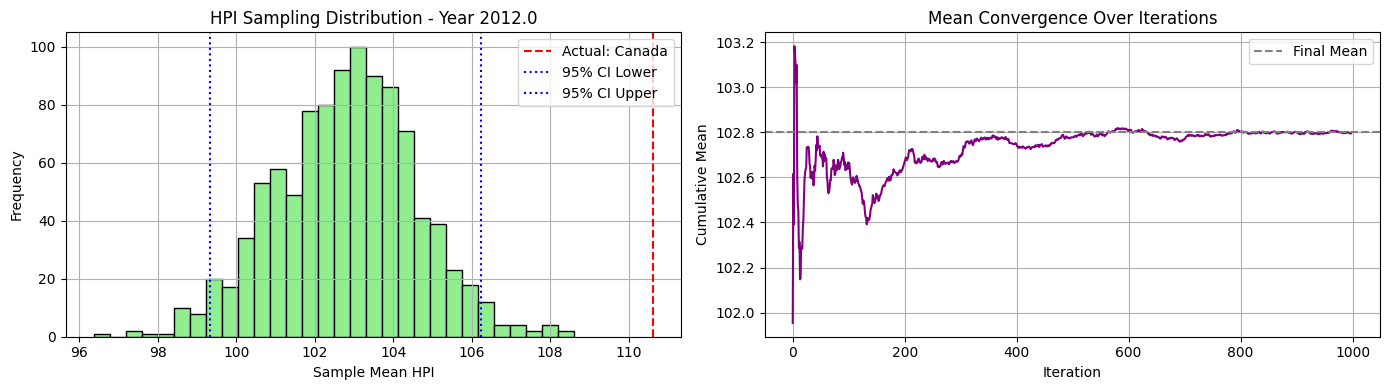


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 122.59 107.59  90.65  94.7   85.58  98.58  99.37 128.77 106.87
 103.13 108.68  85.58 119.18  85.58 124.45  92.38 121.5  107.65 113.42
 130.06 101.21  85.95 114.59 119.98 130.06  92.35  86.7   85.58 115.56
  96.53  90.62 115.41  85.58 109.22 118.3  101.46]


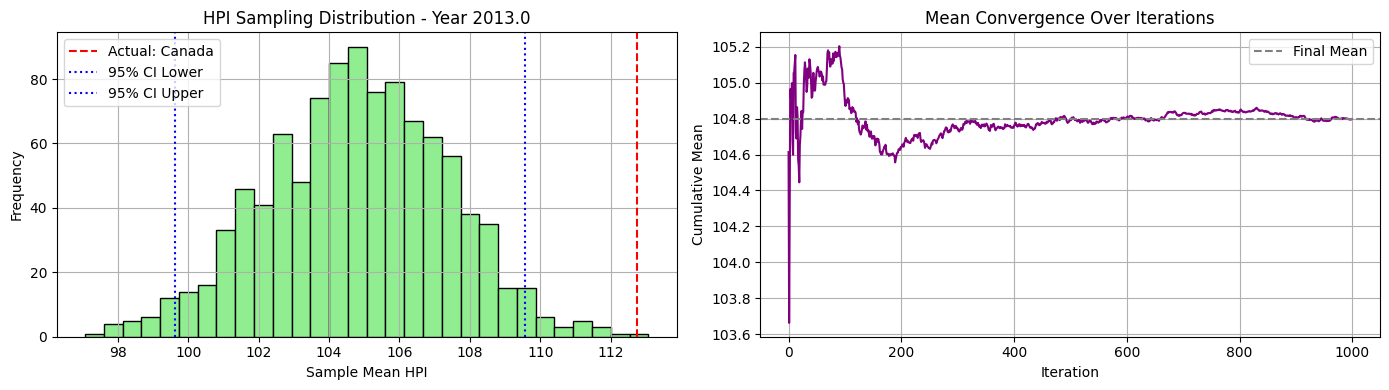


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 126.79 107.22  91.95  93.19  84.64 101.   103.12 146.41 106.5
 101.58 111.85  84.64 128.94  84.66 132.36  88.02 128.78 114.57 118.39
 146.41 103.79  86.66 122.03 123.24 146.41  93.27  90.38  84.64 112.25
  97.8   84.64 123.99  84.64 119.52 121.46 109.6 ]


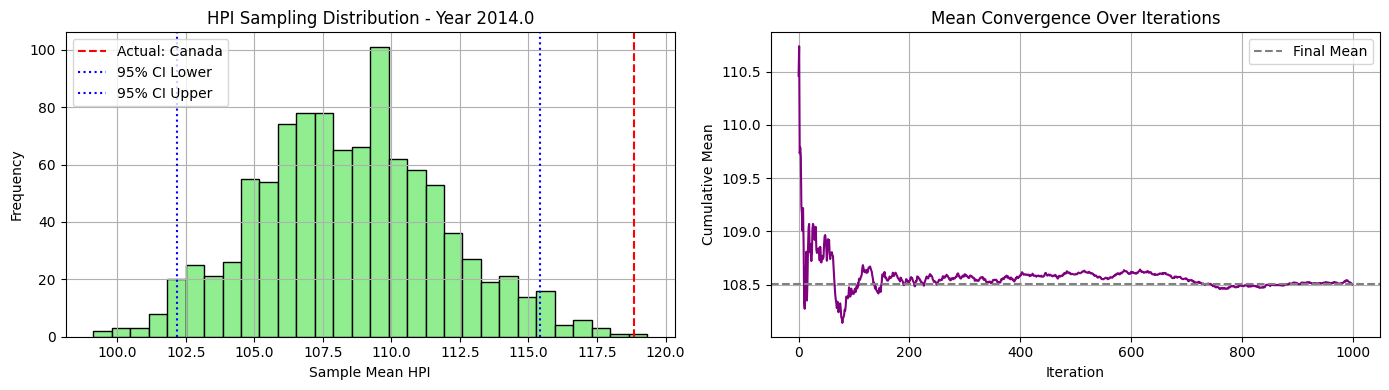


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 132.06 109.17  94.51  90.54  84.67 105.01 110.29 156.46 106.5
 100.22 117.12  84.67 139.74  94.36 140.12  84.67 124.46 118.76 124.78
 156.46 109.83  89.69 137.18 130.76 156.46  94.69  93.15  84.67 107.92
 103.    85.32 131.8   84.67 135.2  124.08 116.12]


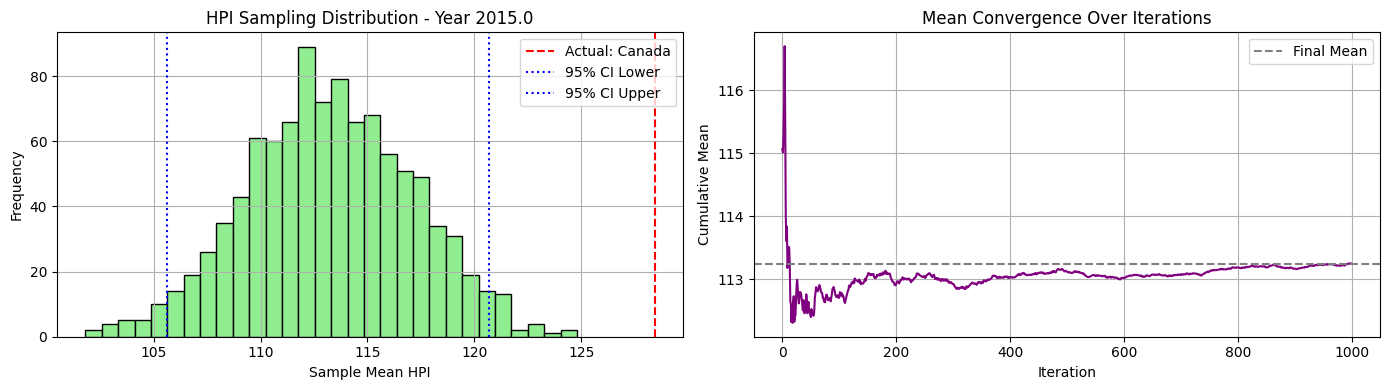


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 141.76 111.72 101.15  91.33  88.1  112.52 115.5  163.86 107.86
 101.25 125.93  88.1  154.59 101.42 150.56  88.1  135.02 125.16 132.28
 164.18 115.82  94.43 156.62 139.95 164.18  96.44  99.78  88.91 104.55
 109.87  88.1  138.22  88.1  146.34 124.32 124.27]


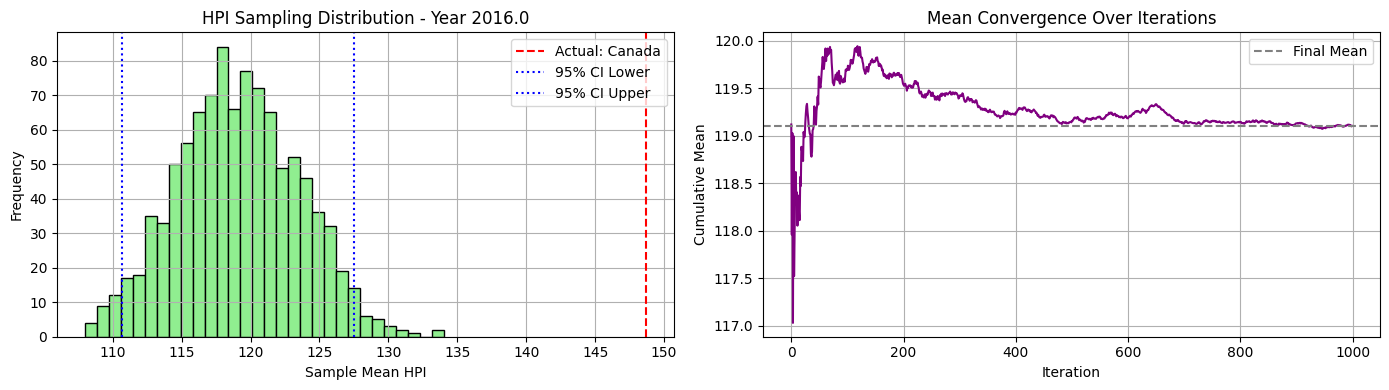


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 147.08 115.66 109.91  94.84  88.54 125.7  120.63 172.91 109.02
 104.46 133.62  88.54 178.56 112.44 156.44  88.54 146.87 136.34 139.69
 178.56 121.94 102.06 166.8  146.91 168.   100.16 108.99  93.93 103.4
 116.3   95.38 143.94  88.54 156.06 125.42 129.93]


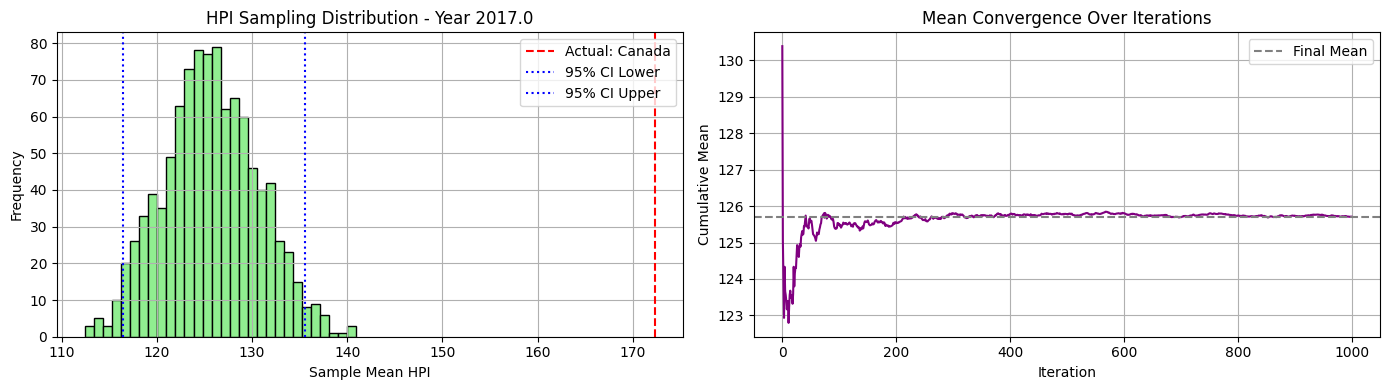


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  157.24 119.16 117.15 100.59  90.72 136.52 126.31 183.13 110.06
 107.52 142.52  90.72 183.82 123.96 155.14  90.72 160.92 146.29 149.55
 183.82 129.02 111.57 172.8  149.04 168.42 106.75 120.19  99.37 111.46
 124.97 103.7  148.96  90.72 154.6  129.16 134.04]


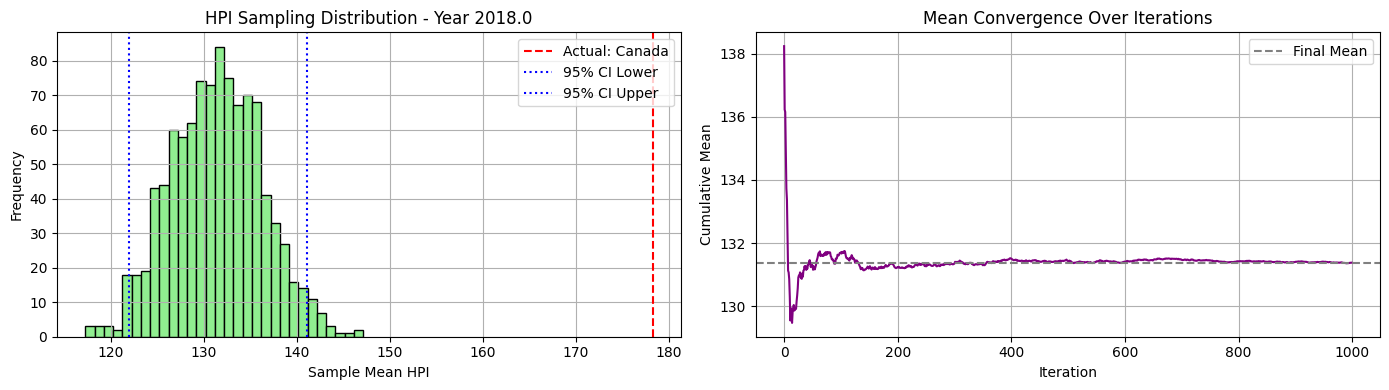


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 163.43 123.62 124.2  109.64  97.25 149.02 129.62 195.98 110.52
 111.1  150.75  97.25 195.98 126.85 158.06  97.25 175.33 156.3  164.68
 195.98 136.9  119.62 178.19 152.73 172.03 116.01 132.16 102.72 113.98
 136.39 110.65 152.69  97.25 158.44 133.99 135.37]


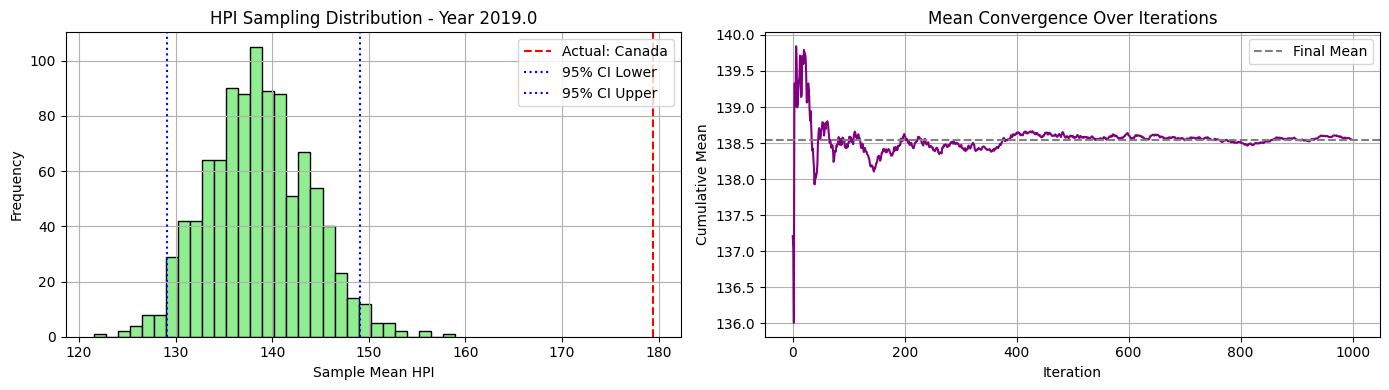


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 174.92 128.92 129.87 118.06 100.19 161.56 136.24 203.12 112.49
 116.89 162.48 100.19 203.12 127.24 162.9  100.19 181.42 167.66 188.57
 198.37 141.54 129.21 196.31 159.24 173.67 128.18 143.75 107.53 115.8
 149.36 115.74 156.31 100.19 165.09 137.31 139.24]


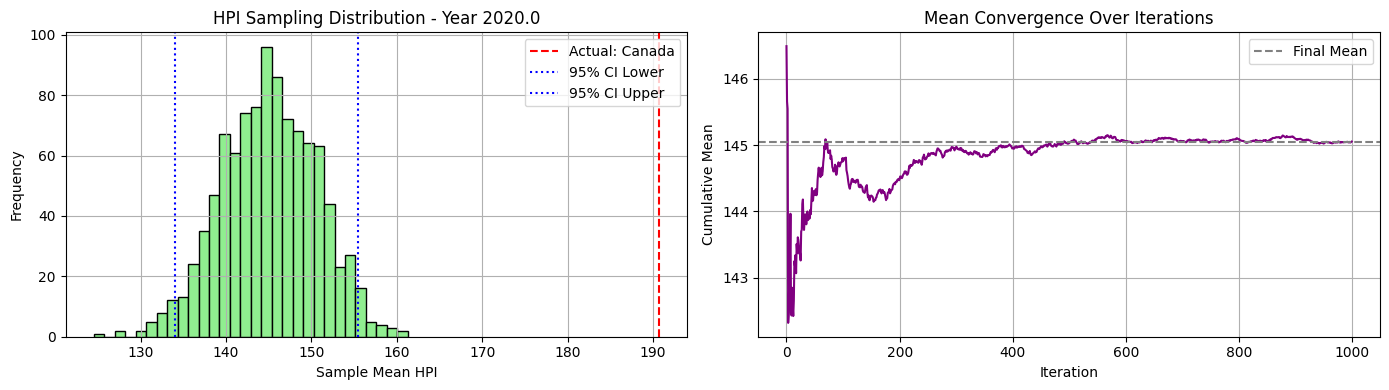


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 195.48 137.52 141.14 126.64 102.55 193.46 152.2  222.1  117.62
 124.38 181.28 102.55 222.1  137.77 176.65 102.55 201.18 194.58 214.81
 200.69 148.74 147.93 222.1  175.91 173.6  139.92 157.27 112.34 125.04
 158.94 129.1  166.82 102.55 181.79 145.16 150.58]


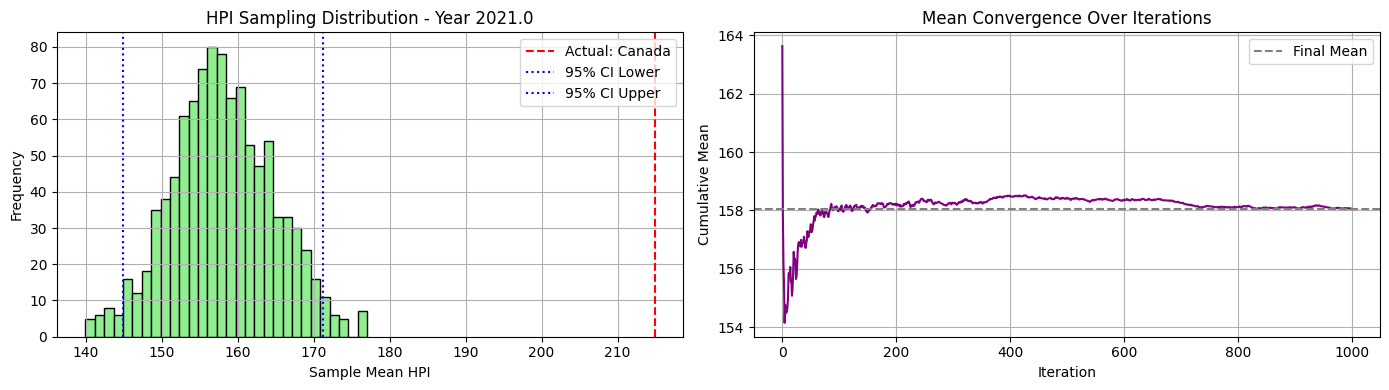


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 215.62 145.12 160.59 145.44 105.52 226.15 151.49 249.69 118.98
 132.1  190.42 105.52 249.69 154.73 207.16 105.52 229.01 231.64 235.34
 207.75 158.62 167.57 249.69 185.13 172.65 156.43 177.14 120.29 137.74
 180.7  148.16 174.03 105.52 188.27 154.42 164.55]


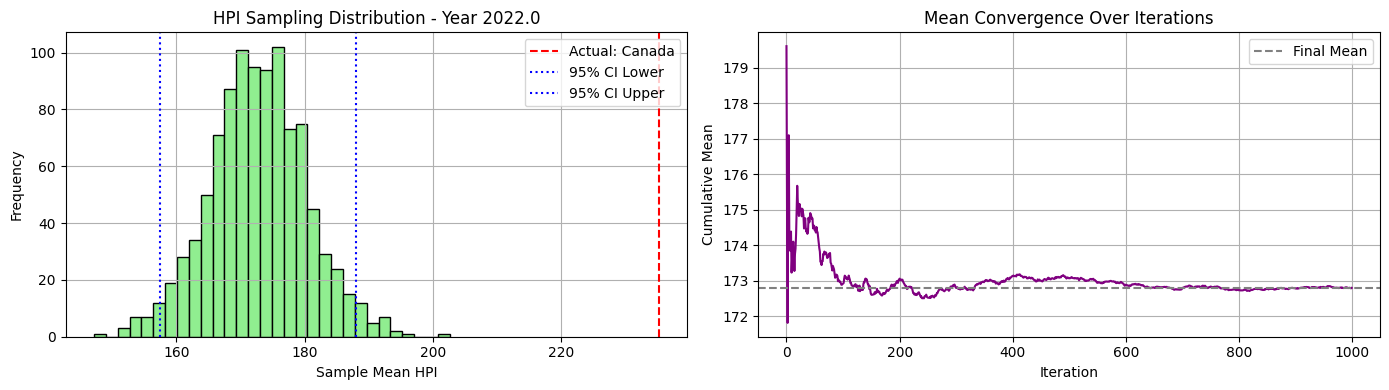


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 212.08 148.52 176.43 162.82 109.76 222.4  151.24 254.38 112.27
 131.52 174.25 109.76 254.38 159.48 214.23 109.76 237.56 254.38 214.
 216.19 168.5  164.36 233.54 184.12 175.16 170.23 191.66 124.06 148.01
 180.36 158.88 176.62 109.76 178.36 157.81 165.  ]


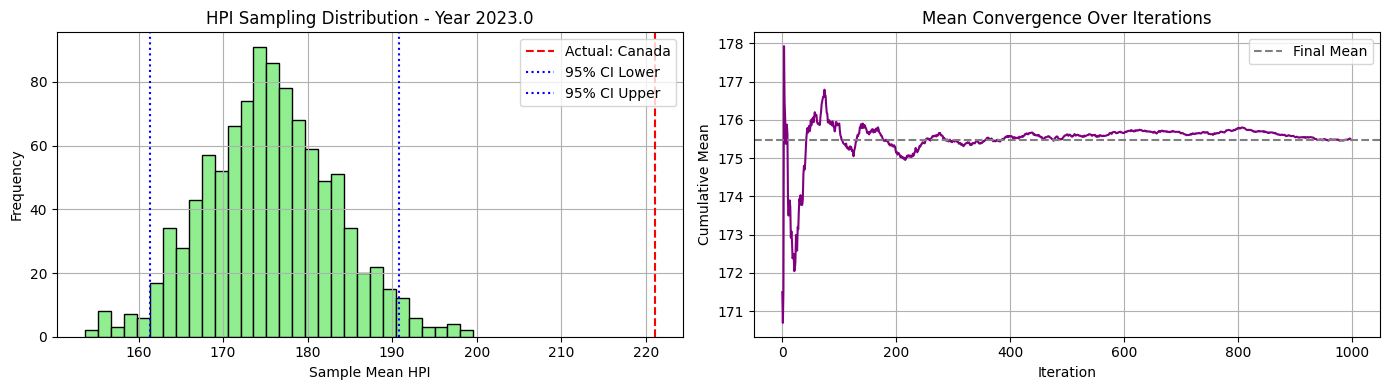


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 207.62 153.31 205.53 179.7  108.31 233.42 156.73 279.12 108.31
 126.68 171.5  108.31 279.12 173.07 224.54 108.31 247.54 279.12 202.74
 225.06 179.35 177.7  233.68 189.05 175.38 195.72 209.06 130.34 155.12
 187.15 170.56 178.1  119.1  178.49 160.56 166.38]


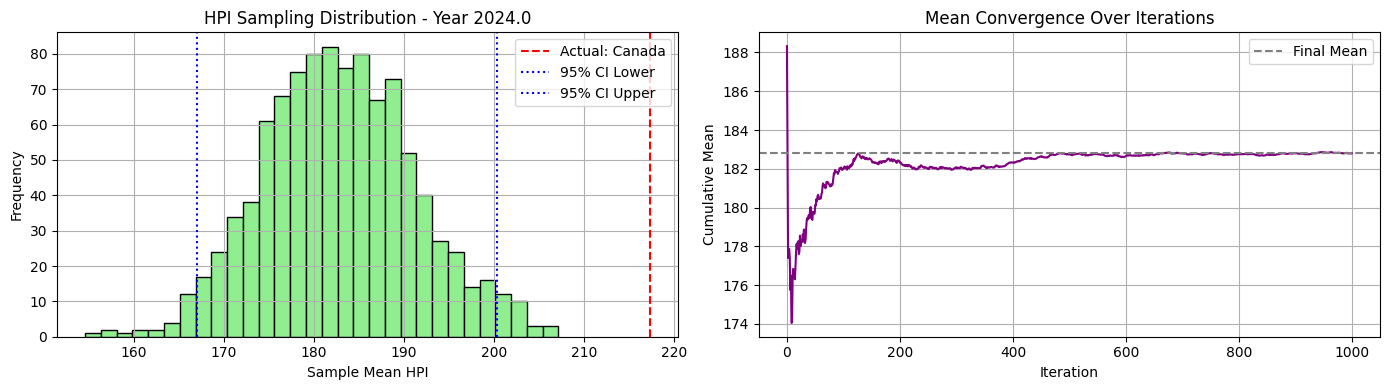

In [42]:
synthetic_c2_ni20_maxi500_h2_32_01, excluded_c2_ni20_maxi500_h2_32_01, actual_c2_ni20_maxi500_h2_32_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, c2_ni20_maxi500, cluster_id=1, seed=32)

### Sampling experiment with seed 46

🔍 Cluster 0 selected. Excluding country: Chile
📊 Sampling from countries: ['Brazil', 'Colombia', 'Hungary', 'Japan', 'Mexico', 'Philippines', 'Russia', 'Serbia', 'South Korea', 'Thailand', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


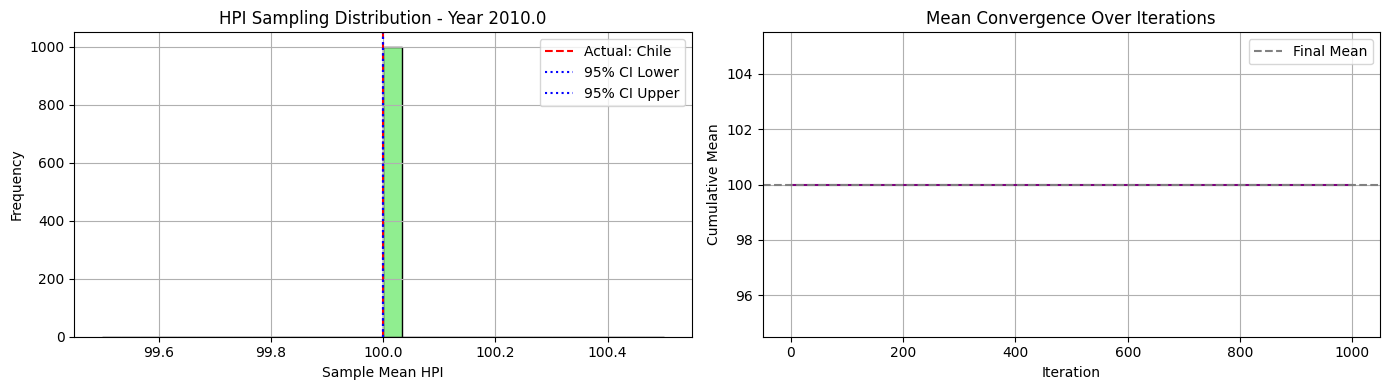


📅 Year 2011.0 - Available HPI values for sampling:
[110.42 107.89  96.56 100.07 105.8  105.57  94.49  97.62 105.23 104.26
  97.24]


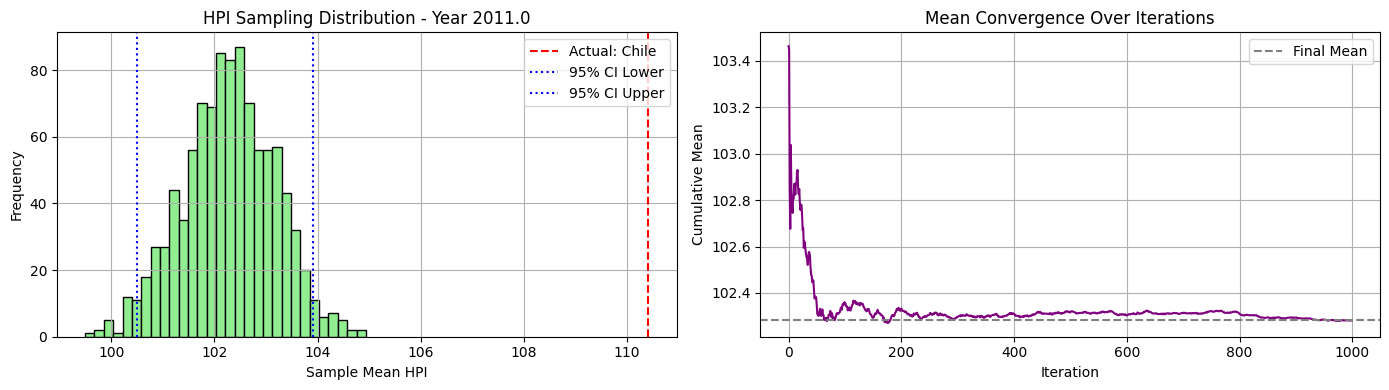


📅 Year 2012.0 - Available HPI values for sampling:
[118.79 118.79  92.98  99.19 109.17 114.94  91.1   95.68 108.25 107.63
 101.82]


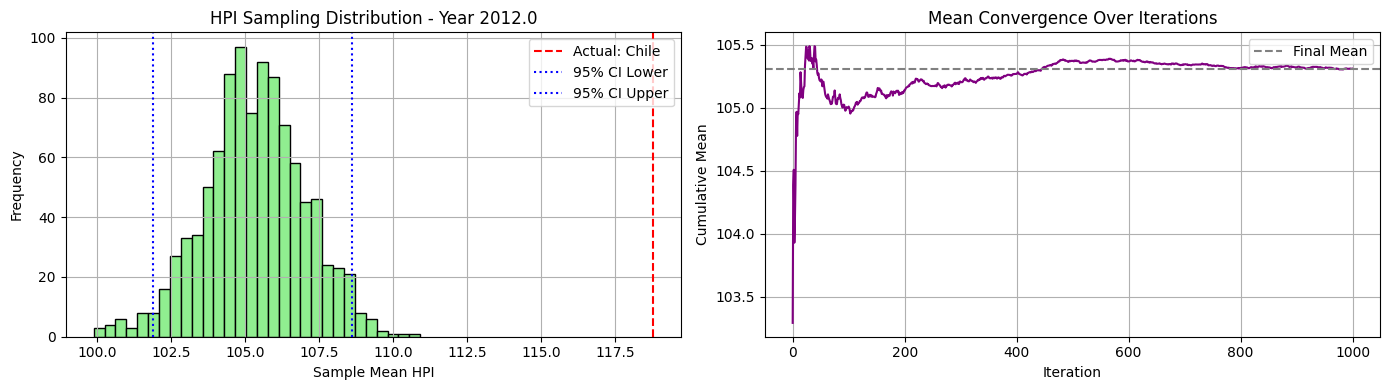


📅 Year 2013.0 - Available HPI values for sampling:
[130.06 130.06  90.58 100.81 114.75 127.86  94.32  90.62 107.8  115.99
 111.83]


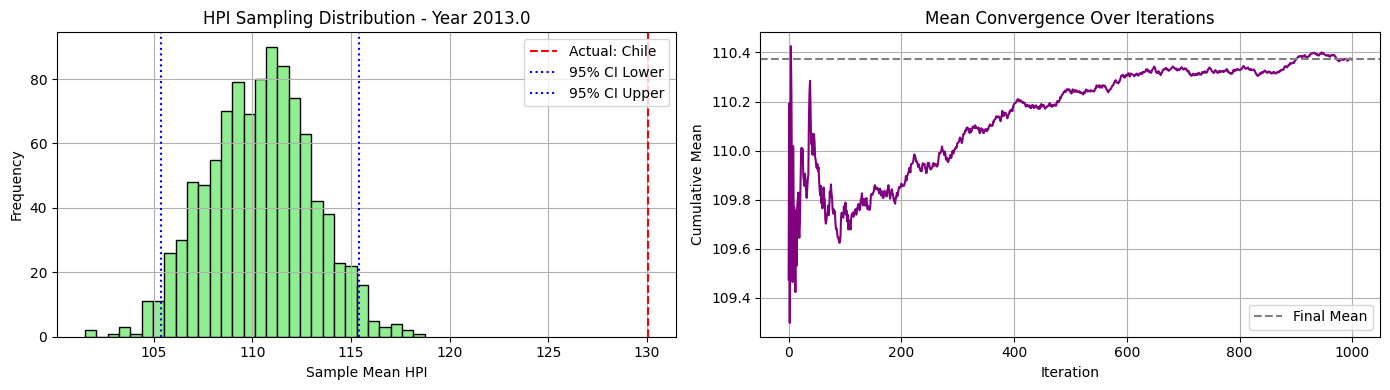


📅 Year 2014.0 - Available HPI values for sampling:
[146.41 140.75  94.37 102.38 119.64 142.76  95.84  95.77 109.43 127.07
 118.88]


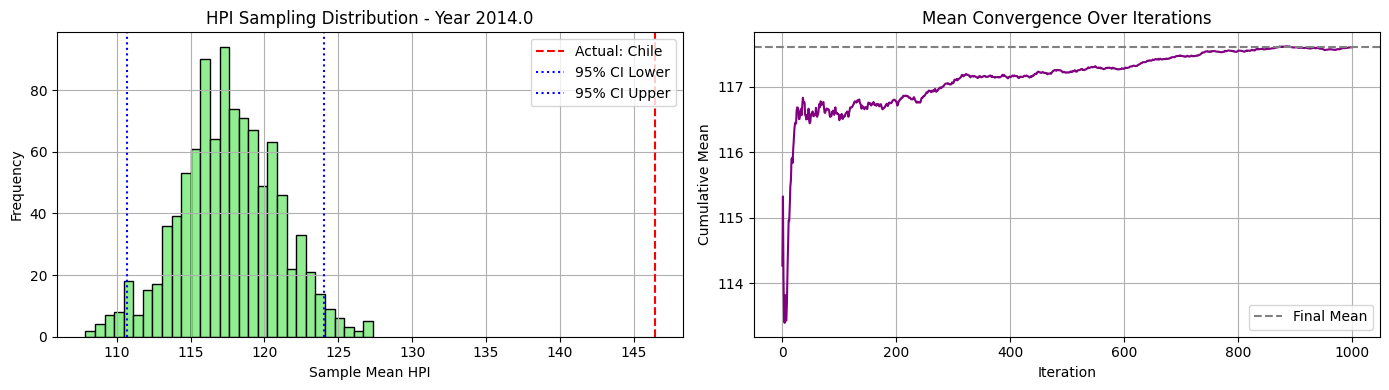


📅 Year 2015.0 - Available HPI values for sampling:
[156.16 152.93 106.75 104.86 129.39 156.46  97.    99.5  113.08 136.
 125.18]


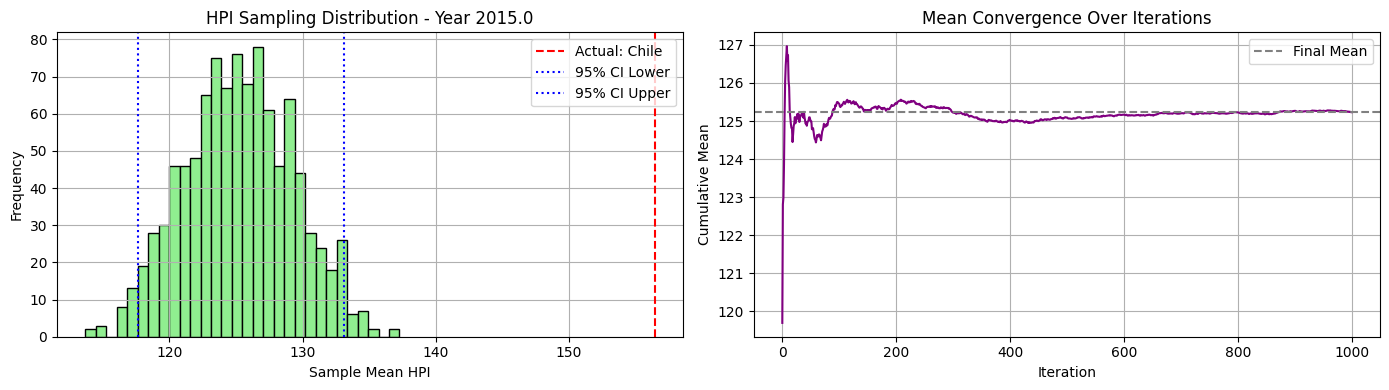


📅 Year 2016.0 - Available HPI values for sampling:
[151.94 164.18 121.03 107.18 138.82 164.18  91.86 110.62 116.09 142.4
 131.88]


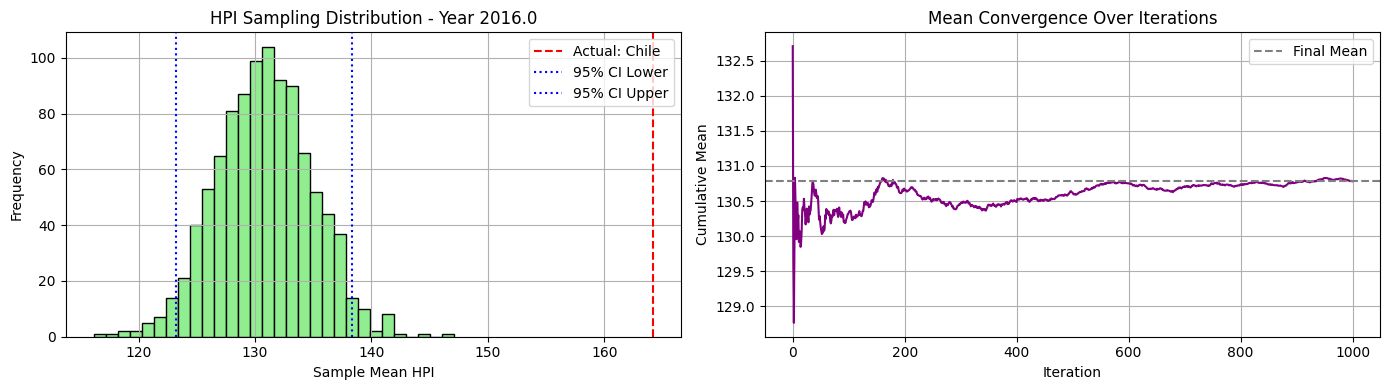


📅 Year 2017.0 - Available HPI values for sampling:
[149.02 178.56 135.84 109.91 149.69 178.56  88.54 115.3  117.6  146.48
 139.61]


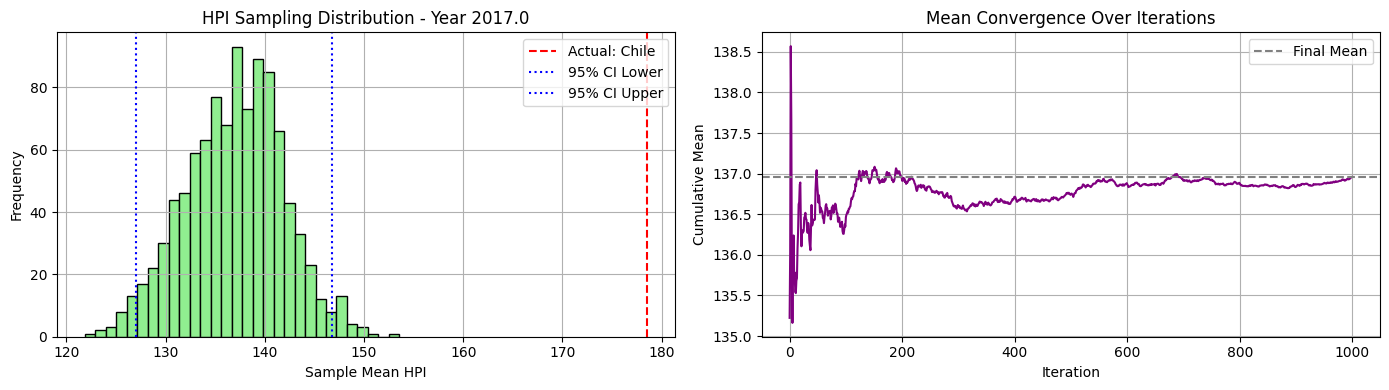


📅 Year 2018.0 - Available HPI values for sampling:
[149.81 183.82 155.3  112.04 162.97 183.82  90.72 123.06 120.22 153.9
 147.35]


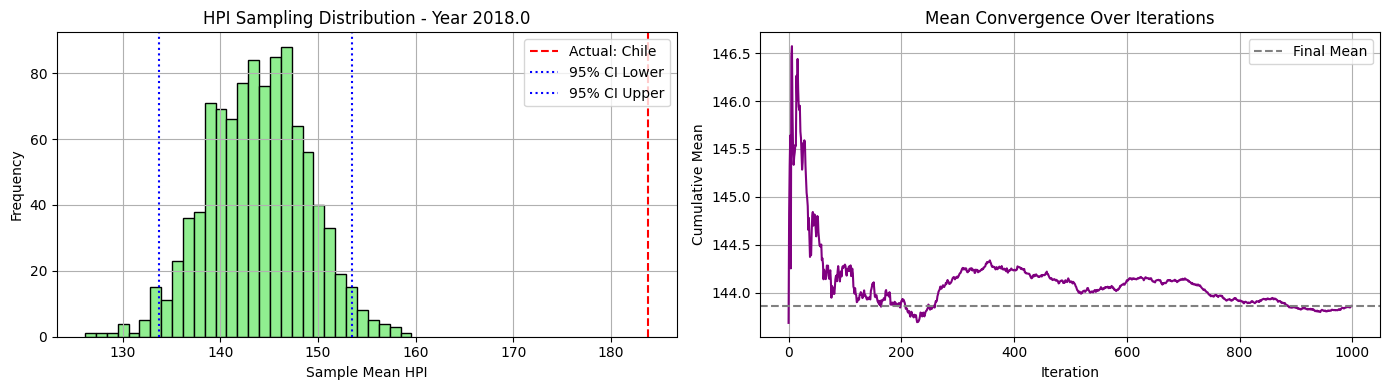


📅 Year 2019.0 - Available HPI values for sampling:
[155.06 195.98 181.64 113.84 176.92 195.26  97.25 135.77 121.93 155.1
 153.14]


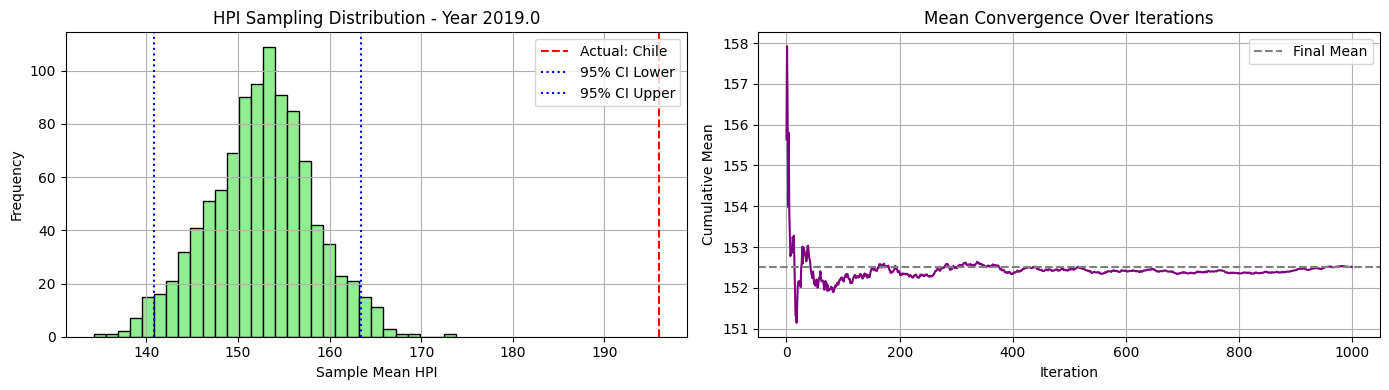


📅 Year 2020.0 - Available HPI values for sampling:
[166.92 203.12 190.63 113.93 187.18 203.12 106.71 149.28 126.56 160.6
 163.52]


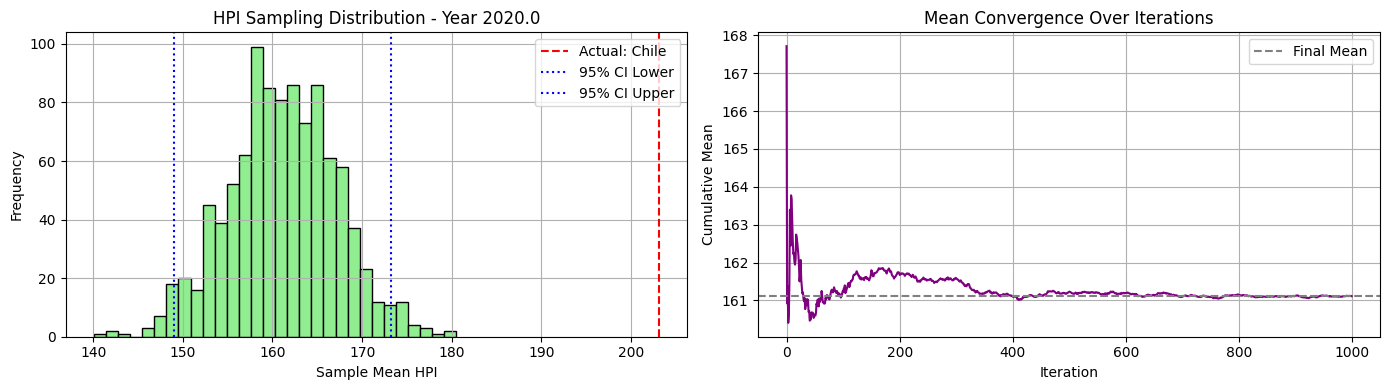


📅 Year 2021.0 - Available HPI values for sampling:
[180.02 214.9  222.1  120.7  201.94 211.74 121.41 166.04 143.73 164.23
 188.56]


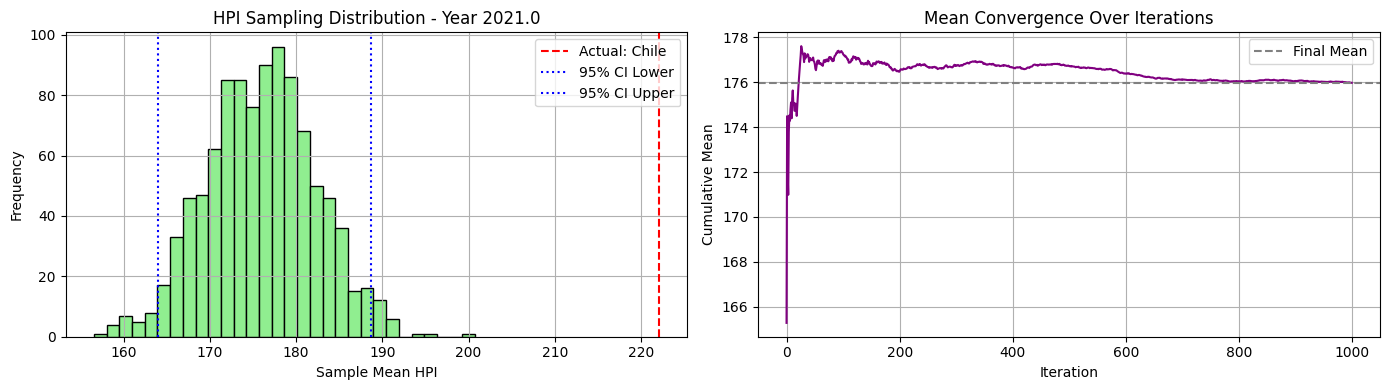


📅 Year 2022.0 - Available HPI values for sampling:
[185.16 230.   249.69 130.84 219.93 223.73 155.16 191.49 153.22 169.16
 213.  ]


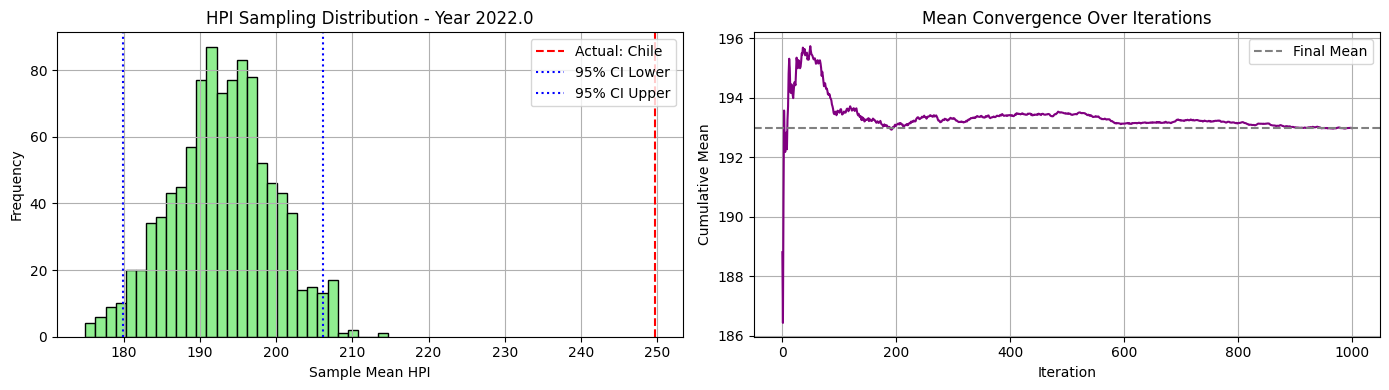


📅 Year 2023.0 - Available HPI values for sampling:
[191.27 245.75 254.38 134.8  243.89 248.04 157.88 209.99 143.99 174.79
 221.72]


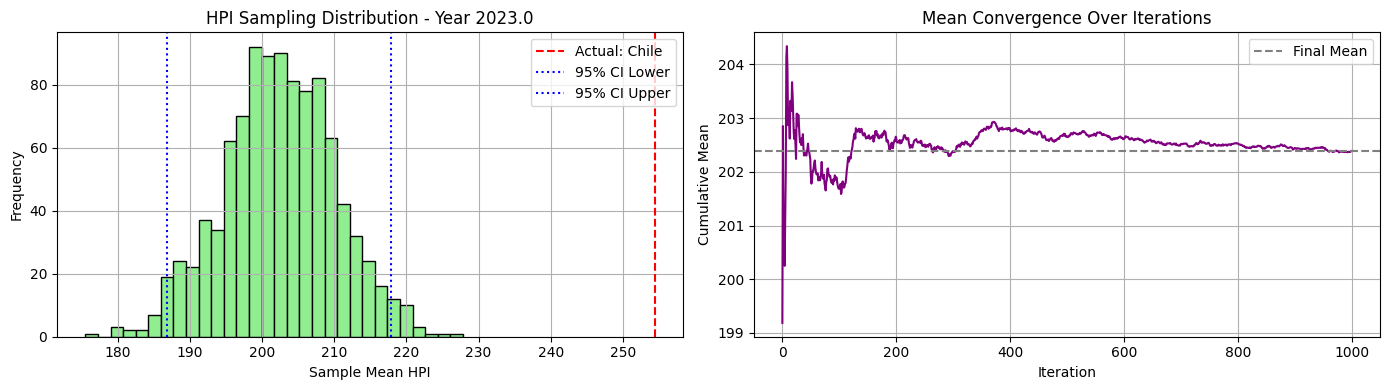


📅 Year 2024.0 - Available HPI values for sampling:
[203.78 269.02 279.12 138.61 266.38 256.03 186.66 220.7  142.46 178.06
 231.23]


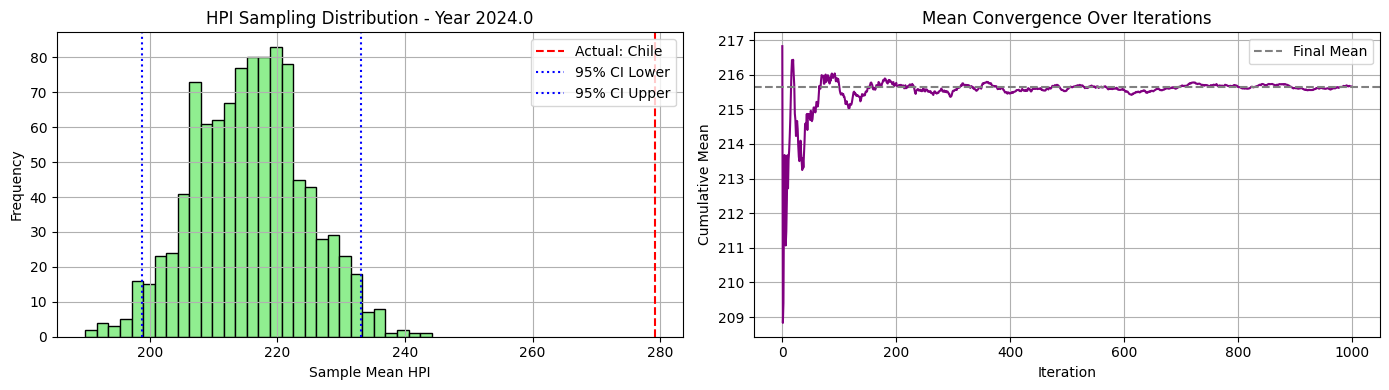

In [43]:
synthetic_c2_ni20_maxi500_h2_46_00, excluded_c2_ni20_maxi500_h2_46_00, actual_c2_ni20_maxi500_h2_46_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, c2_ni20_maxi500, cluster_id=0, seed=46)

🔍 Cluster 1 selected. Excluding country: Canada
📊 Sampling from countries: ['Australia', 'Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Iceland', 'Ireland', 'Israel', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New Zealand', 'Norway', 'Peru', 'Poland', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'United Kingdom']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100.]


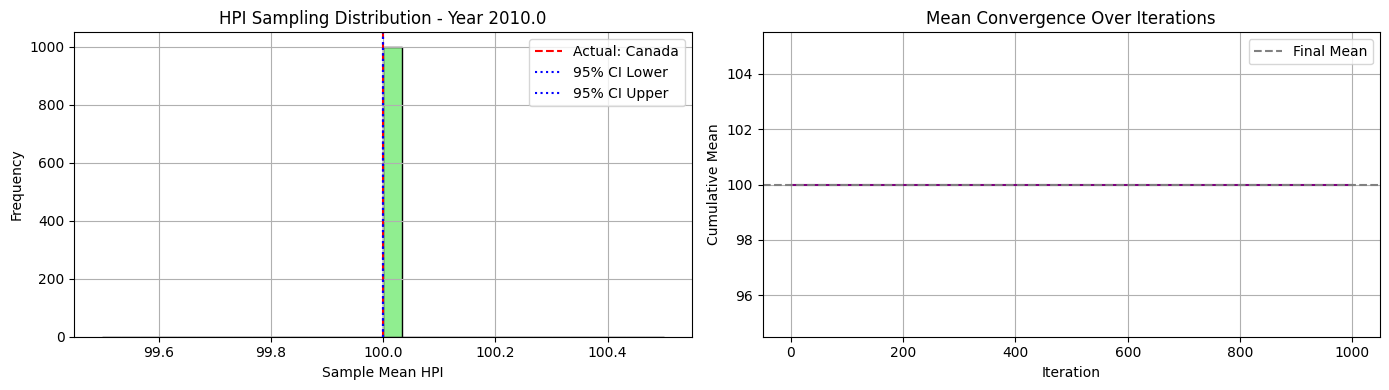


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 104.22 103.58  94.49 100.16  96.68 100.02  98.29 108.47 103.17
 105.69 102.42  94.53 105.5   94.49 110.42 101.36 110.42 106.6  103.68
 109.83  98.63  98.02 100.75 108.01 110.42 100.08  95.1   94.49 109.46
  98.46 102.72 103.59  94.49 102.58 107.51  98.54]


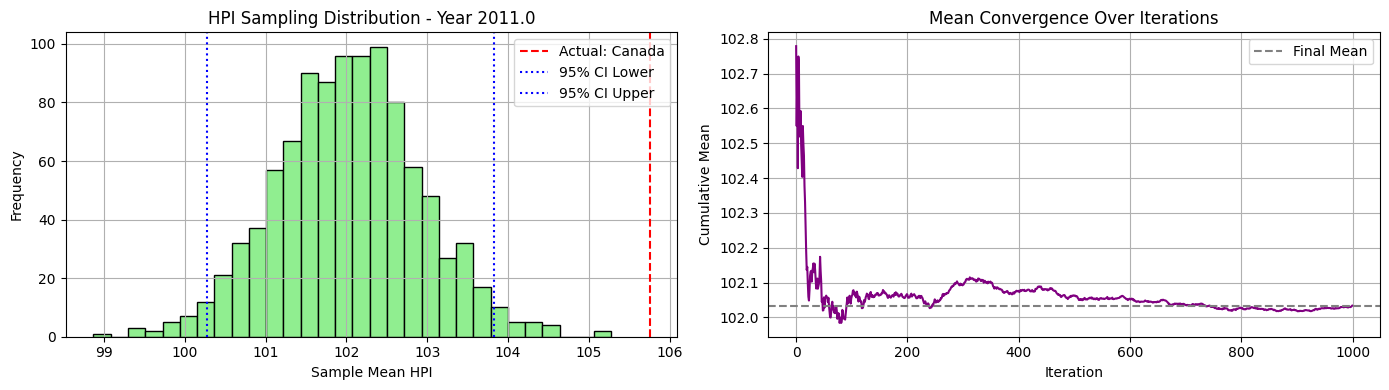


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 117.13 106.02  92.69  98.62  91.54  98.56  95.67 116.34 105.64
 105.11 105.48  88.37 112.38  88.37 114.1   98.77 113.71 106.36 108.03
 118.79 101.62  91.44 105.25 115.34 118.79  96.58  88.37  88.37 112.02
  95.73  95.63 108.41  88.37 103.86 113.72  98.92]


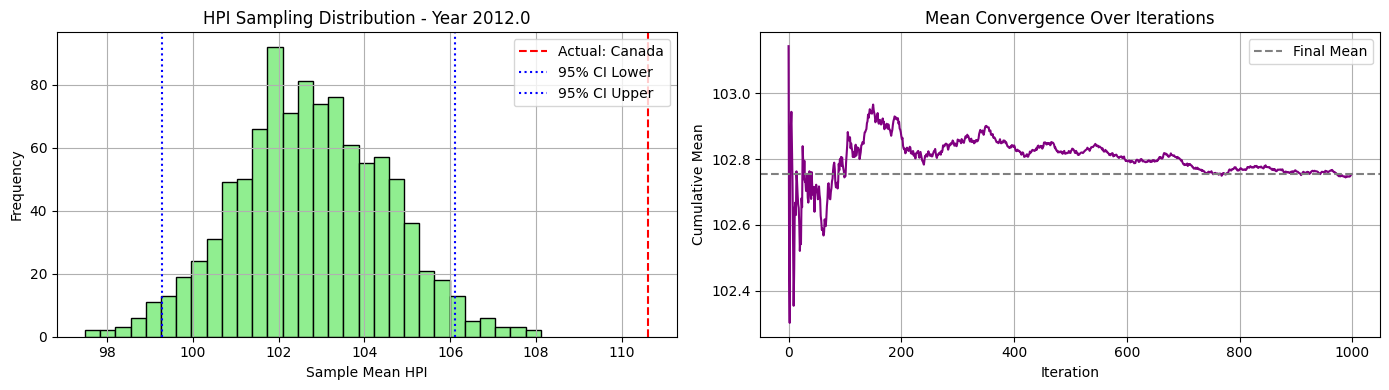


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 122.59 107.59  90.65  94.7   85.58  98.58  99.37 128.77 106.87
 103.13 108.68  85.58 119.18  85.58 124.45  92.38 121.5  107.65 113.42
 130.06 101.21  85.95 114.59 119.98 130.06  92.35  86.7   85.58 115.56
  96.53  90.62 115.41  85.58 109.22 118.3  101.46]


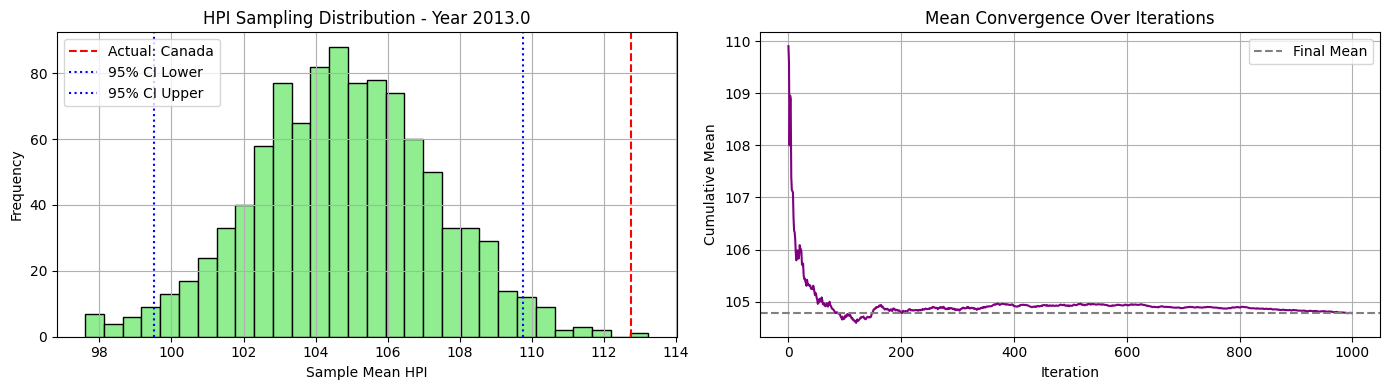


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 126.79 107.22  91.95  93.19  84.64 101.   103.12 146.41 106.5
 101.58 111.85  84.64 128.94  84.66 132.36  88.02 128.78 114.57 118.39
 146.41 103.79  86.66 122.03 123.24 146.41  93.27  90.38  84.64 112.25
  97.8   84.64 123.99  84.64 119.52 121.46 109.6 ]


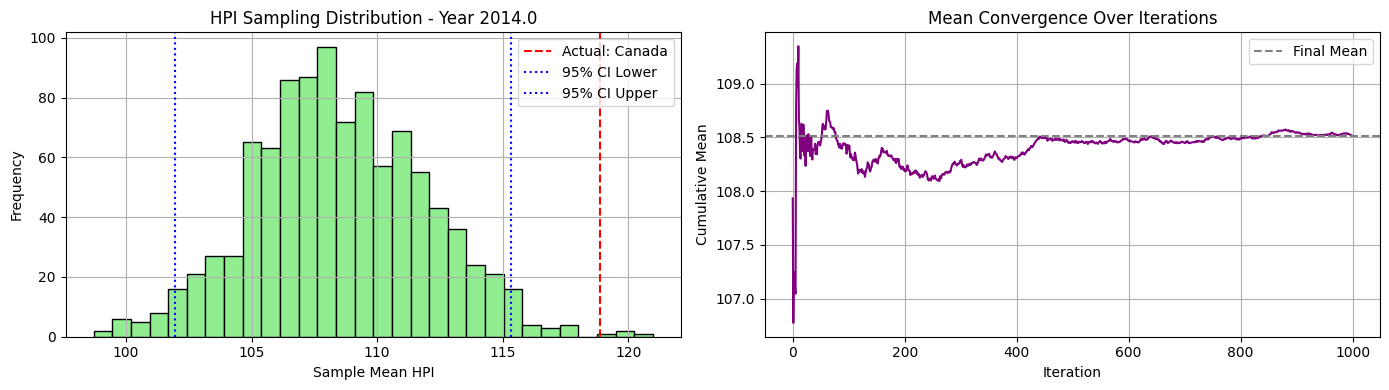


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 132.06 109.17  94.51  90.54  84.67 105.01 110.29 156.46 106.5
 100.22 117.12  84.67 139.74  94.36 140.12  84.67 124.46 118.76 124.78
 156.46 109.83  89.69 137.18 130.76 156.46  94.69  93.15  84.67 107.92
 103.    85.32 131.8   84.67 135.2  124.08 116.12]


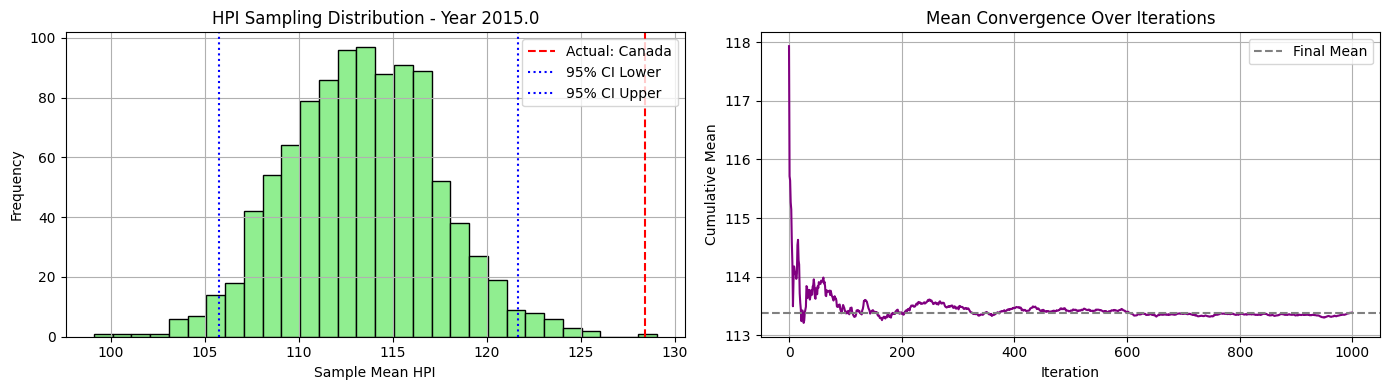


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 141.76 111.72 101.15  91.33  88.1  112.52 115.5  163.86 107.86
 101.25 125.93  88.1  154.59 101.42 150.56  88.1  135.02 125.16 132.28
 164.18 115.82  94.43 156.62 139.95 164.18  96.44  99.78  88.91 104.55
 109.87  88.1  138.22  88.1  146.34 124.32 124.27]


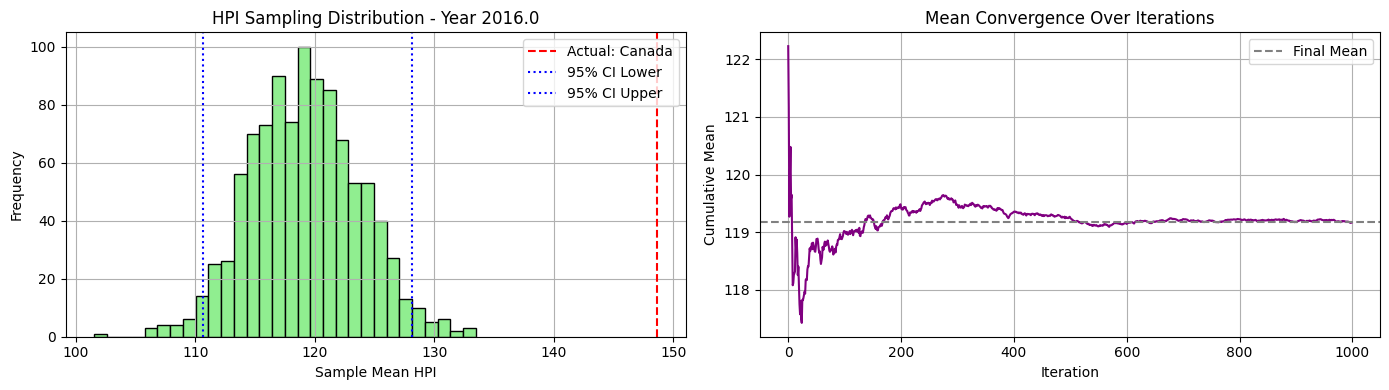


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 147.08 115.66 109.91  94.84  88.54 125.7  120.63 172.91 109.02
 104.46 133.62  88.54 178.56 112.44 156.44  88.54 146.87 136.34 139.69
 178.56 121.94 102.06 166.8  146.91 168.   100.16 108.99  93.93 103.4
 116.3   95.38 143.94  88.54 156.06 125.42 129.93]


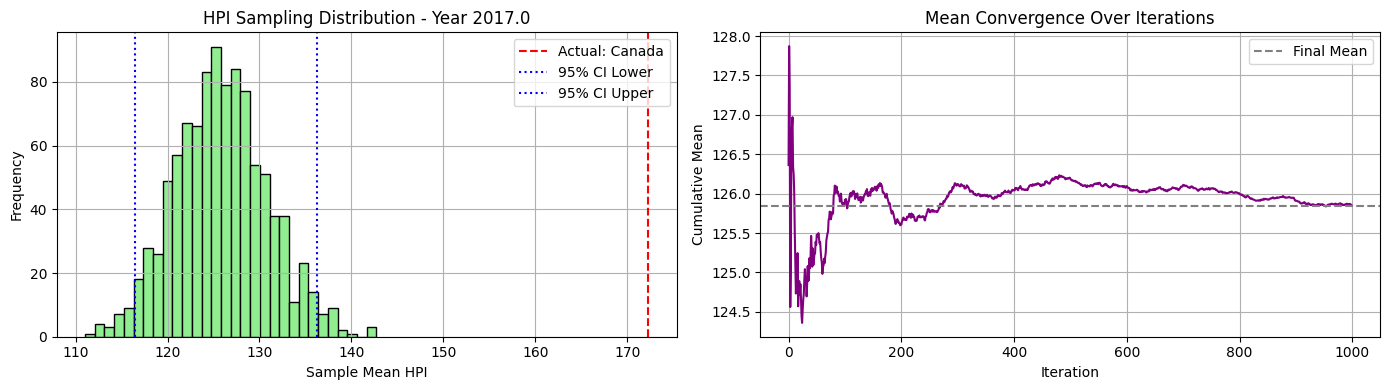


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  157.24 119.16 117.15 100.59  90.72 136.52 126.31 183.13 110.06
 107.52 142.52  90.72 183.82 123.96 155.14  90.72 160.92 146.29 149.55
 183.82 129.02 111.57 172.8  149.04 168.42 106.75 120.19  99.37 111.46
 124.97 103.7  148.96  90.72 154.6  129.16 134.04]


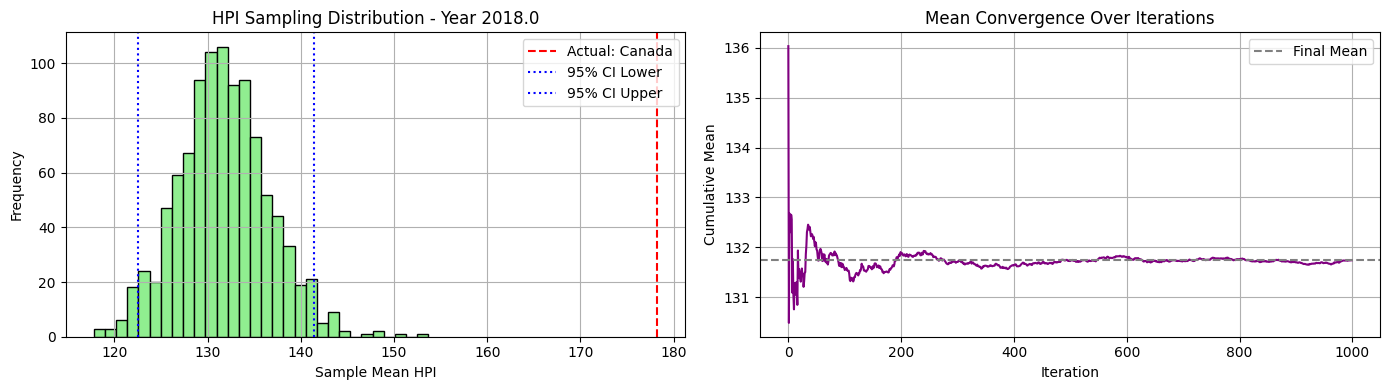


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 163.43 123.62 124.2  109.64  97.25 149.02 129.62 195.98 110.52
 111.1  150.75  97.25 195.98 126.85 158.06  97.25 175.33 156.3  164.68
 195.98 136.9  119.62 178.19 152.73 172.03 116.01 132.16 102.72 113.98
 136.39 110.65 152.69  97.25 158.44 133.99 135.37]


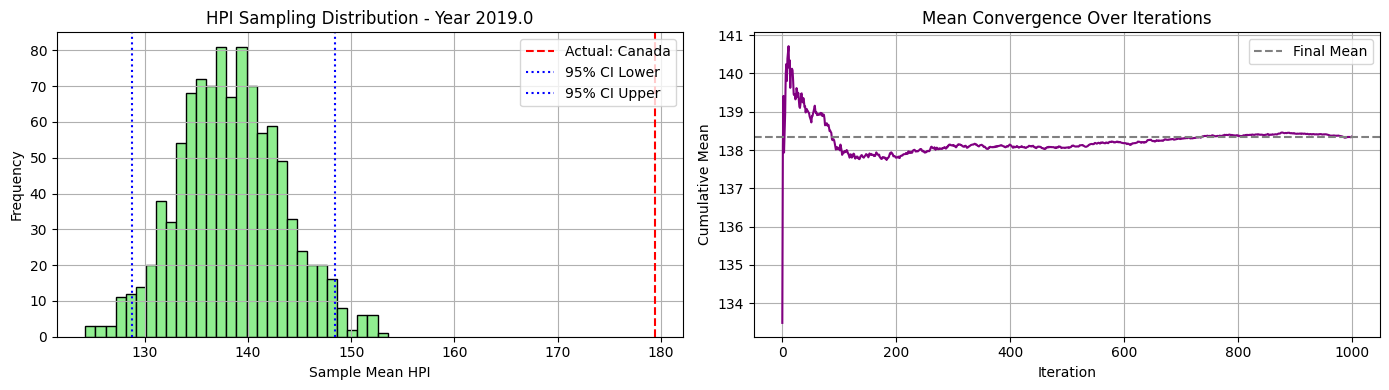


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 174.92 128.92 129.87 118.06 100.19 161.56 136.24 203.12 112.49
 116.89 162.48 100.19 203.12 127.24 162.9  100.19 181.42 167.66 188.57
 198.37 141.54 129.21 196.31 159.24 173.67 128.18 143.75 107.53 115.8
 149.36 115.74 156.31 100.19 165.09 137.31 139.24]


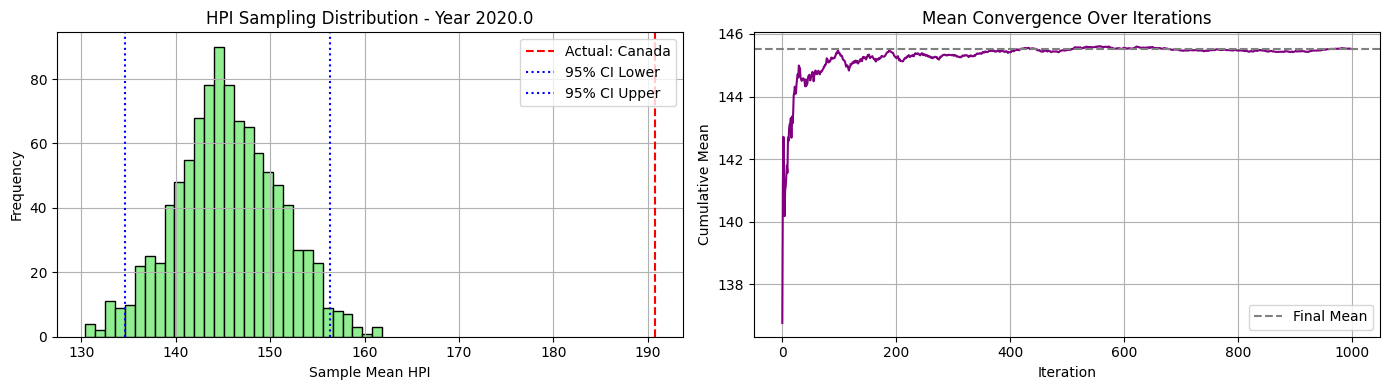


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 195.48 137.52 141.14 126.64 102.55 193.46 152.2  222.1  117.62
 124.38 181.28 102.55 222.1  137.77 176.65 102.55 201.18 194.58 214.81
 200.69 148.74 147.93 222.1  175.91 173.6  139.92 157.27 112.34 125.04
 158.94 129.1  166.82 102.55 181.79 145.16 150.58]


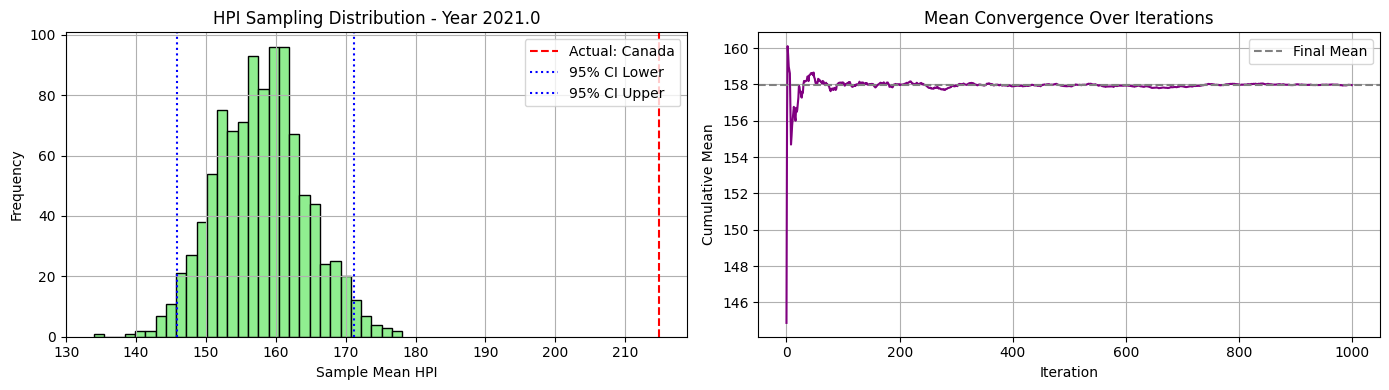


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 215.62 145.12 160.59 145.44 105.52 226.15 151.49 249.69 118.98
 132.1  190.42 105.52 249.69 154.73 207.16 105.52 229.01 231.64 235.34
 207.75 158.62 167.57 249.69 185.13 172.65 156.43 177.14 120.29 137.74
 180.7  148.16 174.03 105.52 188.27 154.42 164.55]


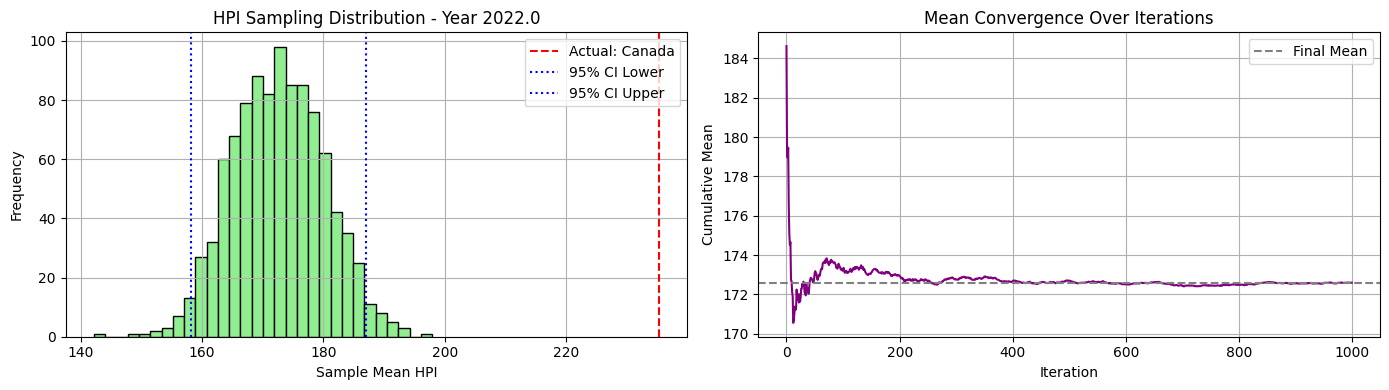


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 212.08 148.52 176.43 162.82 109.76 222.4  151.24 254.38 112.27
 131.52 174.25 109.76 254.38 159.48 214.23 109.76 237.56 254.38 214.
 216.19 168.5  164.36 233.54 184.12 175.16 170.23 191.66 124.06 148.01
 180.36 158.88 176.62 109.76 178.36 157.81 165.  ]


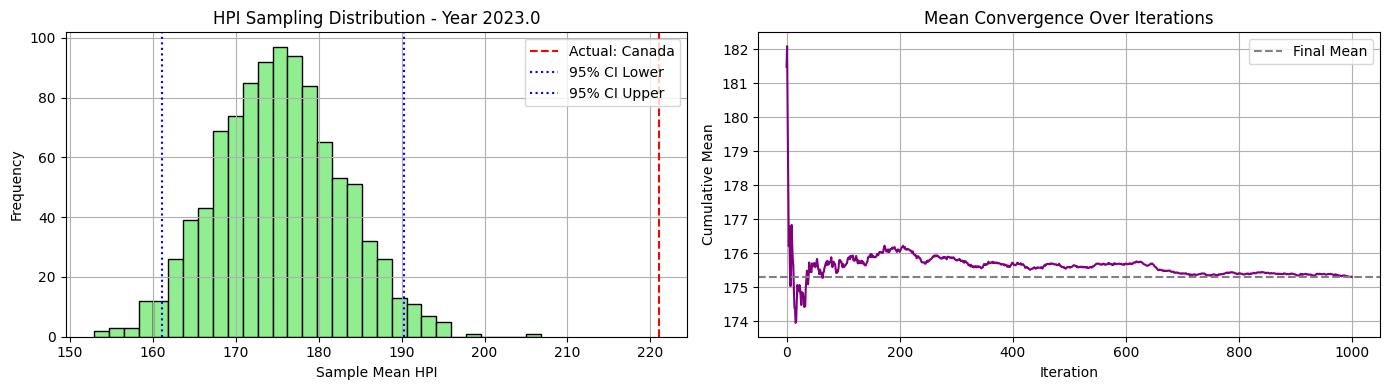


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 207.62 153.31 205.53 179.7  108.31 233.42 156.73 279.12 108.31
 126.68 171.5  108.31 279.12 173.07 224.54 108.31 247.54 279.12 202.74
 225.06 179.35 177.7  233.68 189.05 175.38 195.72 209.06 130.34 155.12
 187.15 170.56 178.1  119.1  178.49 160.56 166.38]


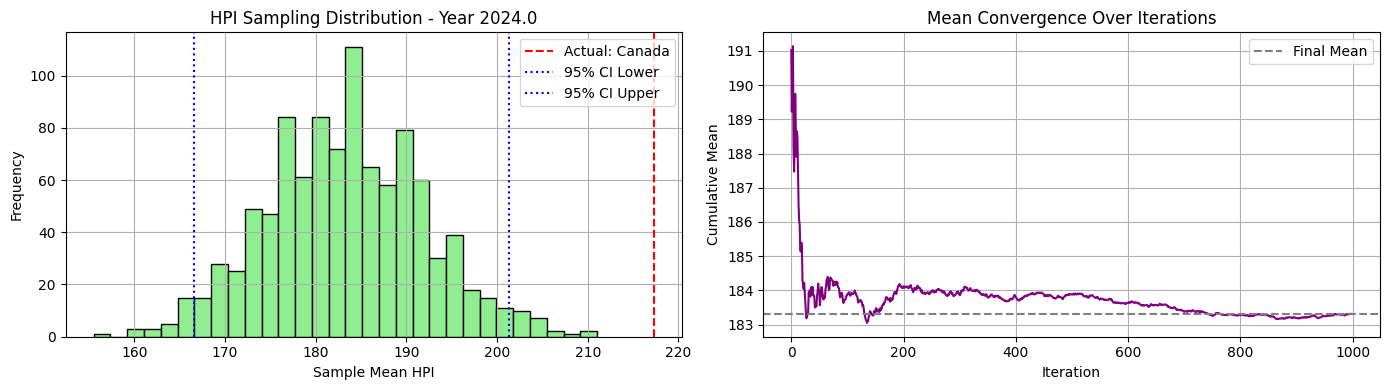

In [44]:
synthetic_c2_ni20_maxi500_h2_46_01, excluded_c2_ni20_maxi500_h2_46_01, actual_c2_ni20_maxi500_h2_46_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, c2_ni20_maxi500, cluster_id=1, seed=46)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [45]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [46]:
def compute_global_mse_mae(synthetic_dicts, actual_dicts):
    """
    Computes global MSE and MAE across multiple synthetic vs. actual HPI dictionaries.

    Parameters:
    - synthetic_dicts: list of dicts with synthetic HPI values per year
    - actual_dicts: list of dicts with actual HPI values per year

    Returns:
    - mse: Mean Squared Error
    - mae: Mean Absolute Error
    """

    y_true = []
    y_pred = []

    for synth, actual in zip(synthetic_dicts, actual_dicts):
        common_years = set(synth.keys()) & set(actual.keys())
        for year in common_years:
            s_val = synth[year]
            a_val = actual[year]
            if not (np.isnan(s_val) or np.isnan(a_val)):
                y_pred.append(s_val)
                y_true.append(a_val)

    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    return mse, mae

In [47]:
import re

def evaluate_all_seeds(synthetic_groups, actual_groups):
    """
    Evaluates multiple sets of synthetic vs. actual HPI dictionaries,
    and stores error metrics in a dictionary keyed by seed number.

    Parameters:
    - synthetic_groups: dict with keys like 'synthetic_42' and values as lists of synthetic dicts
    - actual_groups: dict with keys like 'actual_42' and values as lists of actual dicts

    Returns:
    - metrics_by_seed: dict with seed as key and {'mse': ..., 'mae': ...} as value
    """
    metrics_by_seed = {}

    for synthetic_key in synthetic_groups:
        # Extract seed number from the synthetic key
        match = re.search(r'_(\d+)$', synthetic_key)
        if not match:
            raise ValueError(f"Could not extract seed from key: {synthetic_key}")
        
        seed = int(match.group(1))
        actual_key = f'actual_{seed}'  # construct matching key for actual_groups

        if actual_key not in actual_groups:
            raise KeyError(f"Missing key in actual_groups: {actual_key}")

        synthetic_dicts = synthetic_groups[synthetic_key]
        actual_dicts = actual_groups[actual_key]

        mse, mae = compute_global_mse_mae(synthetic_dicts, actual_dicts)
        metrics_by_seed[seed] = {'mse': mse, 'mae': mae}

    return metrics_by_seed

In [48]:
def summarize_error_metrics(metrics_by_seed):
    """
    Computes the mean and median of MSE and MAE values across multiple seeds.

    Parameters:
    - metrics_by_seed: dictionary with seed as key and {'mse': ..., 'mae': ...} as value

    Returns:
    - summary: dictionary with keys 'mse_mean', 'mse_median', 'mae_mean', 'mae_median'
    """
    mse_values = [metrics['mse'] for metrics in metrics_by_seed.values()]
    mae_values = [metrics['mae'] for metrics in metrics_by_seed.values()]

    summary = {
        'mse_mean': np.mean(mse_values),
        'mse_median': np.median(mse_values),
        'mae_mean': np.mean(mae_values),
        'mae_median': np.median(mae_values)
    }

    return summary

In [49]:
a = [synthetic_c2_ni20_maxi500_h2_23_00, synthetic_c2_ni20_maxi500_h2_23_01]
b = [actual_c2_ni20_maxi500_h2_23_00, actual_c2_ni20_maxi500_h2_23_01]

c = [synthetic_c2_ni20_maxi500_h2_32_00, synthetic_c2_ni20_maxi500_h2_32_01]
d = [actual_c2_ni20_maxi500_h2_32_00, actual_c2_ni20_maxi500_h2_32_01]

e = [synthetic_c2_ni20_maxi500_h2_46_00, synthetic_c2_ni20_maxi500_h2_46_01]
f = [actual_c2_ni20_maxi500_h2_46_00, actual_c2_ni20_maxi500_h2_46_01]

In [50]:
synth_c2_ni20_maxi500_h2 = {
    'synthetic_32': a,
    'synthetic_43': c,
    'synthetic_52': e
}

actual_c2_ni20_maxi500_h2 = {
    'actual_32': b,
    'actual_43': d,
    'actual_52': f
}

In [51]:
results_c2_ni20_maxi500_h2 = evaluate_all_seeds(synth_c2_ni20_maxi500_h2, actual_c2_ni20_maxi500_h2)

In [52]:
for seed, metrics in results_c2_ni20_maxi500_h2.items():
    print(f"🔢 Seed {seed} → MSE: {metrics['mse']:.4f}, MAE: {metrics['mae']:.4f}")

🔢 Seed 32 → MSE: 1727.7408, MAE: 33.5875
🔢 Seed 43 → MSE: 1413.4703, MAE: 32.4391
🔢 Seed 52 → MSE: 1414.3055, MAE: 32.4385


In [54]:
summary_c2_ni20_maxi500_h2 = summarize_error_metrics(results_c2_ni20_maxi500_h2)

In [55]:
print("📈 Error Summary Across Seeds:")
print(f"Mean MSE: {summary_c2_ni20_maxi500_h2['mse_mean']:.4f}")
print(f"Median MSE: {summary_c2_ni20_maxi500_h2['mse_median']:.4f}")
print(f"Mean MAE: {summary_c2_ni20_maxi500_h2['mae_mean']:.4f}")
print(f"Median MAE: {summary_c2_ni20_maxi500_h2['mae_median']:.4f}")

📈 Error Summary Across Seeds:
Mean MSE: 1518.5055
Median MSE: 1414.3055
Mean MAE: 32.8217
Median MAE: 32.4391


### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [56]:
from datetime import datetime

In [57]:
log_df = pd.read_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')

In [58]:
pd.set_option('display.max_columns', None)

In [59]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score
22,kmeans_plusplus_c2_ni20_maxi500_3_countries_ex...,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.131965,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,873.227083,19.651486
23,kmeans_plusplus_c3_ni20_maxi500_3_countries_ex...,2025-09-14 22:16,"Winsorization, RobustScaler",53,KMeans,3,k-means++,20.0,500.0,42,True,True,1,0.105738,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,1564.283633,27.561166
24,kmeans_plusplus_c2_ni20_maxi500_5_27deleted_wi...,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.408223,"RobustScaler, log transformation",Winsorization x5,True,False,"Winsorization, rounding",Winsorization x2,bootstrap,"[23, 32, 46]",3.0,657.423582,19.836296
25,kmeans_plusplus_c2_ni20_maxi500_h2_3_countries...,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,557.401153,18.076755
26,kmeans_plusplus_c2_ni20_maxi500_h2_same_seeds_...,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,276.897625,12.785992


In [60]:
new_entry_c2_ni20_maxi500_h2 = {
    'experiment_name': 'kmeans_plusplus_c2_ni20_maxi500_diff_and_3deleted_countries_in_hpi_3_countries_exclude',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhoutte_c2_ni20_maxi500,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': 'Winsorization',
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'bootstrap',
    'mse_score': summary_c2_ni20_maxi500_h2['mse_mean'],
    'mae_score': summary_c2_ni20_maxi500_h2['mae_mean'],
    'sampling_seed': (23,32,46),
    'excluded_countries_count': 3,
    'used_all_variables_for_clustering': True,
    'used_pca_for_clustering': False,
    "premacroecon_conversion_transform": None,
    "countries_used_for_clustering": 50
}

In [61]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry_c2_ni20_maxi500_h2])], ignore_index=True)

In [62]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score
23,kmeans_plusplus_c3_ni20_maxi500_3_countries_ex...,2025-09-14 22:16,"Winsorization, RobustScaler",53,KMeans,3,k-means++,20.0,500.0,42,True,True,1,0.105738,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,1564.283633,27.561166
24,kmeans_plusplus_c2_ni20_maxi500_5_27deleted_wi...,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.408223,"RobustScaler, log transformation",Winsorization x5,True,False,"Winsorization, rounding",Winsorization x2,bootstrap,"[23, 32, 46]",3.0,657.423582,19.836296
25,kmeans_plusplus_c2_ni20_maxi500_h2_3_countries...,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,557.401153,18.076755
26,kmeans_plusplus_c2_ni20_maxi500_h2_same_seeds_...,2025-09-16 18:52,None,53,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,276.897625,12.785992
27,kmeans_plusplus_c2_ni20_maxi500_diff_and_3dele...,2025-09-16 21:11,None,50,KMeans,2,k-means++,20.0,500.0,42,True,True,1,0.359740,"StandardScaler, log transformation",Winsorization,True,False,"Winsorization, rounding",Winsorization,bootstrap,"(23, 32, 46)",3.0,1518.505534,32.821709


In [64]:
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)

In [65]:
log_df.to_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')